# Giriş

Bu projede hastalıksız ve zatürreye sahip kişilerin röntgen görüntülerinin bulunduğu PneumoniaMINST veri seti kullanılmıştır. Bir model tamamen temiz röntgen görüntüleri ile mükemmel bir şekilde zatürre tanısı yapabilirken, gerçek hayatta her zaman tertemiz görüntüler ile karşılaşılması mümkün olmayabilir. Bu nedenle modellerin bu gibi durumlarda ne kadar iyi çalıştığını gözlemlemek için classification, olasılık kalibrasyonu ve Grad-CAM haritaları beraber kullanılmıştır.

Projedeki asıl soru ise, noise, blur ve düşürülmüş kontrastın modellerin çıktılarına etkisi ne olduğudur. Sıfırdan eğitilen bir CNN modeli ile, veri setinde bulunan röntgen görüntüleri ile fine-tune edilmiş bir ResNet18 modeli kullanılmıştır. Opsiyonel olarak rastgele gürültü, bulanıklık ve kontrast kullanılan ikinci bir model eğitilmiştir. Bu model ile amaçlanan ise, eğitim için kullanılan görüntülerdeki bu değişikliklerin bozulmuş görüntülerde modelin başarısı artarken, bozulmamış görüntülerde modelin başarısının azalıpazalmadığını ölçmektir.

Bu notebook'un çalıştırılmaması için ekstra bir dependancye ihtiyaç yoktur, `requirements.txt` projenin veri deposundan otomatik olarak şuanda kullandığınız ortama indirilecektir.

## Requirements dosyası indirilmesi

Bir sonraki hücrede kullanılması için proje reposundan 'requirements.txt' dosyasını indirir.

In [ ]:
# study-cell: requirements-download
from pathlib import Path
from urllib.request import urlopen

REQUIREMENTS_URL = "https://github.com/keeremarslaan/ML-w-PneumoniaMNIST/raw/refs/heads/main/requirements.txt"
downloaded_requirements_path = None
if REQUIREMENTS_URL.strip():
    with urlopen(REQUIREMENTS_URL.strip(), timeout=30) as response:
        requirements_text = response.read().decode('utf-8')
    if not requirements_text.strip():
        raise ValueError('Dosya boş.')
    downloaded_requirements_path = Path('runs/bootstrap/requirements.txt')
    downloaded_requirements_path.parent.mkdir(parents=True, exist_ok=True)
    downloaded_requirements_path.write_text(requirements_text, encoding='utf-8')
    print('Requirements indirildi:', downloaded_requirements_path)
else:
    print('Dosya bağlantısı çalışmıyor veya bozuk, bağlantığı kontrol edin.')


Dosya bağlantısı çalışmıyor veya bozuk, bağlantığı kontrol edin.


## Gerekli Paketlerin yüklenmesi

'Requirements.txt' üzerinde bulunan paketlerin indirilmesi ve kurulması. Eğer 'Requirements.txt' bulunamazsa kod içerisinde hali hazırda bulunan liste üzerinden ortam kurulur.

In [2]:
# study-cell: dependencies
from pathlib import Path
import importlib.metadata as package_metadata
import os
import subprocess
import sys

assert sys.version_info >= (3, 10), 'Use Python 3.10 or newer.'
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
REQUIREMENTS = 'torch>=2.5,<3\ntorchvision>=0.20,<1\nmedmnist==3.0.2\nnumpy>=1.26,<3\npandas>=2.2,<4\nmatplotlib>=3.9,<4\nscikit-learn>=1.5,<2\nscipy>=1.13,<2\nPillow>=10,<14\npackaging>=24,<27\ncaptum>=0.8,<1\ntqdm>=4.66,<5\nPyYAML>=6,<7\n'
dependency_source = 'embedded list'
if downloaded_requirements_path is not None:
    repository_specs = [line.strip() for line in downloaded_requirements_path.read_text(encoding='utf-8').splitlines()
                        if line.strip() and not line.lstrip().startswith('#')]
    if repository_specs != REQUIREMENTS.splitlines():
        raise ValueError('GitHub üzerinden elde edilen liste ile kodda bulunan liste uyuşmamaktadır. Başlamadan önce iki kopyanın da uyuştuğundan emin olun.')
    dependency_source = str(downloaded_requirements_path)
try:
    from packaging.requirements import Requirement
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'packaging>=24,<27'], check=True)
    from packaging.requirements import Requirement

missing = []
for specification in REQUIREMENTS.splitlines():
    requirement = Requirement(specification)
    try:
        version = package_metadata.version(requirement.name)
    except package_metadata.PackageNotFoundError:
        version = None
    if version is None or version not in requirement.specifier:
        missing.append(specification)
if any(Requirement(s).name in {'torch', 'torchvision'} for s in missing):
    missing = list(dict.fromkeys(missing + ['torch>=2.5,<3', 'torchvision>=0.20,<1']))
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
print('Dependency listesi şu şekilde doğrulandı:', dependency_source)


Dependency listesi şu şekilde doğrulandı: embedded list


## Projede kullanılan ayarlar

Tüm proje ayarları 'cfg' sözlüğü içerisindedir. Ayarları düzenlemek için 'config.yaml' dosyasının düzenlenmesine gerek yoktur, alt hücre üzerinden yapılabilir. 'config.yaml' sadece bu hücrede bulunan 'cfg' dosyasının arşivlenmesi için .yaml dosyasına dönüştürülmüş halidir.

Batch büyüklüğü 64 olarak seçildi ve, her model en fazla 20 epoch eğitiliyor, eğer son 5 epoch ile elde edlien clean-validation AUROC skoru artış göstermediyse, eğitim son epochta bitiriliyor ve en yüksek AUROC skoruna sahip model seçiliyor. Smoke modu test için kullanılır, notebook test edilmediği sürece deaktif edilmelidir.

Notebookda bir ayar değiştirilmesi durumunda, bu değişiklik altta bulunan hücre üzerinde yapılmalı ve hücre yeniden çalıştırılmalı.

In [ ]:
# study-cell: configuration
cfg = {'project': {'name': 'pneumoniamnist-quality',
             'protocol_version': 2,
             'reproduction_version': 'standalone_v1'},
 'dataset': {'name': 'pneumoniamnist',
             'resolution': 128,
             'positive_label': 1,
             'positive_name': 'pneumonia',
             'official_splits': ['train', 'val', 'test']},
 'paths': {'data': 'runs/data',
           'checkpoints': 'runs/checkpoints',
           'outputs': 'runs/results',
           'prediction_cache': 'runs/cache'},
 'execution': {'mode': 'full',
               'device': 'auto',
               'num_workers': 0,
               'cpu_threads': 4,
               'deterministic_algorithms': True,
               'reuse_completed_checkpoints': True,
               'progress': {'enabled': True, 'mininterval_seconds': 0.5, 'leave': True},
               'smoke': {'train_samples': 128,
                         'val_samples': 64,
                         'max_epochs': 1,
                         'batch_size': 16,
                         'subset_seed': 31415},
               'auto_download_colab_backups': True},
 'seeds': {'training': [42, 123, 2026], 'primary': 42, 'corruption': 8675309},
 'exploratory-data-analysis': {'examples_per_class': 4, 'intensity_histogram_bins': 25},
 'models': {'cnn': {'channels': [16, 32, 64],
                    'block': 'conv3_bn_relu_maxpool2',
                    'pooling': 'adaptive_average',
                    'dropout': 0.2,
                    'normalization': {'mean': [0.5], 'std': [0.5]}},
            'resnet18': {'weights': 'IMAGENET1K_V1',
                         'input_channels': 3,
                         'output_logits': 1,
                         'fine_tuning': 'all_parameters',
                         'batchnorm_policy': 'train_running_stats_in_training_eval_stats_in_validation',
                         'normalization': {'mean': [0.485, 0.456, 0.406],
                                           'std': [0.229, 0.224, 0.225]}}},
 'augmentation': {'training_only': True,
                  'affine_degrees': 5,
                  'affine_translate': [0.02, 0.02],
                  'interpolation': 'bilinear',
                  'fill': 0.5,
                  'flips': False,
                  'quality_corruptions': False},
 'training': {'loss': 'BCEWithLogitsLoss',
              'class_weighting': 'none',
              'optimizer': 'AdamW',
              'learning_rate_cnn': 0.001,
              'learning_rate_resnet_backbone': 0.0001,
              'learning_rate_resnet_head': 0.001,
              'weight_decay': 0.0001,
              'batch_size': 64,
              'max_epochs': 20,
              'early_stopping': {'monitor': 'clean_val_auroc', 'patience': 5, 'min_delta': 0.0},
              'checkpoint_rule': 'highest_clean_val_auroc_then_earliest_epoch',
              'architecture_selection': 'primary_seed_clean_val_auroc_only',
              'architecture_tie_preference': 'cnn',
              'tie_tolerance': 1e-12,
              'mixed_precision': False},
 'threshold': {'method': 'youden_j',
               'split': 'val',
               'condition': 'clean',
               'candidates': 'unique_validation_logits_mapped_to_probabilities_plus_zero_and_one',
               'comparison': 'probability_greater_than_or_equal',
               'tie_rule': 'largest_threshold_within_tolerance',
               'tie_tolerance': 1e-12},
 'corruptions': {'input_range': [0.0, 1.0],
                 'order': 'grayscale_float_then_one_corruption_then_channels_then_normalization',
                 'noise': {'std': [0.03, 0.07, 0.12],
                           'mean': 0.0,
                           'clip': True,
                           'field': 'per_split_and_sample_index_cpu_generator_shared_across_severities'},
                 'blur': {'sigma': [0.5, 1.0, 2.0], 'kernel_size': 13, 'padding': 'reflect'},
                 'contrast': {'factors': [0.8, 0.6, 0.4],
                              'operation': 'torchvision.transforms.functional.adjust_contrast'}},
 'calibration': {'method': 'temperature_scaling',
                 'fit_split': 'val',
                 'fit_condition': 'clean',
                 'objective': 'unweighted_binary_nll',
                 'optimizer': 'bounded_scalar_log_temperature',
                 'temperature_bounds': [0.05, 20.0],
                 'optimizer_xatol': 1e-08,
                 'ece_bins': 15,
                 'ece_convention': 'positive_class_equal_width',
                 'decision_policy': 'map_threshold_and_verify_identical_labels'},
 'gradcam': {'model': 'resnet18',
             'seed': 42,
             'layer': 'layer4[-1].conv2',
             'target': 'raw_pneumonia_logit',
             'positive_attributions': True,
             'examples_per_group': 3,
             'groups': ['TP', 'TN', 'FP', 'FN'],
             'selection': 'ascending_official_test_index',
             'opacity': 0.4,
             'shared_scale': 'within_image_across_four_conditions'},
 'metrics': {'auprc': 'average_precision',
             'class_order': [0, 1],
             'f1_zero_division': 0,
             'undefined_rates': 'nan',
             'seed_sd_ddof': 1},
 'robustness': {'enabled': True,
                'artifact_namespace': 'robustness_v1',
                'interpretation': 'exploratory_after_baseline_test_exposure',
                'model': 'resnet18',
                'seeds': [42, 123, 2026],
                'policy': {'families': ['clean', 'noise', 'blur', 'contrast'],
                           'probabilities': [0.25, 0.25, 0.25, 0.25],
                           'noise_range': [0.0, 0.12],
                           'blur_range': [0.5, 2.0],
                           'contrast_range': [0.4, 1.0],
                           'order': 'affine_then_one_quality_family_then_channels_then_normalization',
                           'composition': False},
                'comparison': 'paired_robust_minus_baseline_per_seed',
                'refit_on_test': False}}

# YAML dosyası olarak ayarların kayıt edilmesi
import yaml

def export_configuration(destination):
    destination = Path(destination)
    snapshot = ('# Notebook üzerinden ayarlar dosyası oluşturuldu\n'
                '# Yeniden bu dosyayı oluşturmak için notebook üzerinden gerekli hücreyi çalıştırın.\n'
                + yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
    if destination.exists():
        if destination.read_text(encoding='utf-8') != snapshot:
            raise FileExistsError(f'Hali hazırda var olan ayarlar ile snapshot farklı. Lütfen mevcut dosyayı koruyun ve inceleyin.')
    else:
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_text(snapshot, encoding='utf-8')
    return destination


## Runtime
Verinin training kısmı model eğitimleri için kullanılır. Validation kısmı ise checkpointler arasında ve modeller arasında seçimde bulunmak, threshold ve sıcaklık ölçekleme parametrelerini belirlemek için kullanılır.
Projede kullanılan split, verinin orjinalinde bulunan split ile aynıdır ve değiştirilmemiştir.


In [4]:
# study-cell: runtime
import hashlib
import json
import platform
import random
import time
from datetime import datetime, timezone

from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.transforms import functional as TF, InterpolationMode
from torchvision.models import ResNet18_Weights
import medmnist
from medmnist import INFO, PneumoniaMNIST
import sklearn
import captum
from IPython.display import display

started_at = time.perf_counter()
ROOT = Path.cwd().resolve()
config_bytes = json.dumps(cfg, sort_keys=True).encode()

def progress(iterable=None, *, desc, unit='step', total=None, leave=None):
    options = cfg['execution']['progress']
    return tqdm(iterable, total=total, desc=desc, unit=unit,
                disable=not options['enabled'], mininterval=options['mininterval_seconds'],
                leave=options['leave'] if leave is None else leave, dynamic_ncols=True)

assert cfg['dataset']['name'] == 'pneumoniamnist'
assert cfg['dataset']['resolution'] == 128
assert cfg['execution']['mode'] in {'smoke', 'full'}

TEST_GATE = False
assert cfg['seeds']['training'] == [42, 123, 2026] and cfg['seeds']['primary'] == 42
assert cfg['corruptions']['noise']['mean'] == 0.0 and cfg['corruptions']['noise']['clip']
assert cfg['corruptions']['blur']['padding'] == 'reflect'
assert cfg['corruptions']['blur']['kernel_size'] % 2 == 1
assert cfg['corruptions']['blur']['kernel_size'] >= 6 * max(cfg['corruptions']['blur']['sigma']) + 1
assert cfg['corruptions']['contrast']['operation'] == 'torchvision.transforms.functional.adjust_contrast'
assert cfg['corruptions']['order'] == 'grayscale_float_then_one_corruption_then_channels_then_normalization'
assert cfg['corruptions']['noise']['field'] == 'per_split_and_sample_index_cpu_generator_shared_across_severities'
assert cfg['augmentation']['training_only'] and not cfg['augmentation']['flips']
assert not cfg['augmentation']['quality_corruptions']
assert cfg['augmentation']['interpolation'] == 'bilinear'
ROBUST = False

def local_path(relative):
    path = (ROOT / relative).resolve()
    if not path.is_relative_to(ROOT):
        raise ValueError('Oluşturulan dosya ve klasör yolları, projenin ana klasörünün içinde kalmalıdır.')
    return path

MODE = cfg['execution']['mode']
DATA = local_path(cfg['paths']['data'])
ARTIFACT_MODE = Path('baseline') / MODE
OUTPUT = local_path(cfg['paths']['outputs']) / ARTIFACT_MODE
FIGURES = OUTPUT / 'figures'
for directory in (DATA, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
torch.set_num_threads(cfg['execution']['cpu_threads'])
torch.use_deterministic_algorithms(cfg['execution']['deterministic_algorithms'])
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = cfg['execution']['deterministic_algorithms']
seed_all(cfg['seeds']['primary'])
requested_device = cfg['execution']['device']
available_device = ('cuda' if torch.cuda.is_available() else
                    'mps' if torch.backends.mps.is_available() else 'cpu')
device = torch.device(available_device if requested_device == 'auto' else requested_device)
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA requested but unavailable.')
if device.type == 'mps' and not torch.backends.mps.is_available():
    raise RuntimeError('MPS requested but unavailable.')

if MODE == 'full':
    assert device.type == 'cuda' and sys.platform.startswith('linux'), 'Colab üzerinden bir GPU seçin, ya da CPU ve MPS ile smoke mode üzerinden çalıştırın.'

def file_hash(path, algorithm='sha256'):
    digest = hashlib.new(algorithm)
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, content):
    Path(path).write_text(json.dumps(content, indent=2, allow_nan=False) + '\n')

package_names = [Requirement(s).name for s in REQUIREMENTS.splitlines()]
cpu_model = platform.processor() or platform.machine()
host_memory_bytes = None
if sys.platform == 'darwin':
    cpu_model = subprocess.check_output(['sysctl', '-n', 'machdep.cpu.brand_string'], text=True).strip()
    host_memory_bytes = int(subprocess.check_output(['sysctl', '-n', 'hw.memsize'], text=True).strip())
runtime = {
    'timestamp_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version.split()[0], 'platform': platform.platform(),
    'machine': platform.machine(), 'cpu_model': cpu_model,
    'host_memory_bytes': host_memory_bytes, 'device': str(device),
    'cuda_available': torch.cuda.is_available(),
    'mps_available': torch.backends.mps.is_available(),
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else
           f'{cpu_model} (MPS; unified memory)' if device.type == 'mps' else None,
    'gpu_memory_bytes': torch.cuda.get_device_properties(0).total_memory if torch.cuda.is_available() else None,
    'packages': {name: package_metadata.version(name) for name in package_names},
    'config_sha256': hashlib.sha256(config_bytes).hexdigest(),
    'mode': MODE,
    'deterministic_algorithms': torch.are_deterministic_algorithms_enabled(),
}
runtime['progress'] = {**cfg['execution']['progress'], 'tqdm_version': package_metadata.version('tqdm')}

print('Device:', device, '| Python:', runtime['python'], '| torch:', runtime['packages']['torch'])


Device: cuda | Python: 3.13.16 | torch: 2.14.1+cu130


## Verinin İndirilmesi ve Doğrulanması

Resmi veri seti 4.708 training, 524 validation ve 624 adet test görüntüsü içermekte. Verisetinden sadece 128x128 pixel boyutundaki siyah beyaz röntgen görüntüleri alınmıştır. Hastalığı bulunmayan görüntüler 0 labelına sahipken, zatürre bulunan görüntüler 1 labelına sahiptir. Verideki tüm splitlerde zatürre bulunan görüntü oranı daha fazladır, sırasıyla training, validation ve test için bu oranlar; 1.214/3494, 135/389 ve 234/390'dır.

In [5]:
# study-cell: data
data_started = time.perf_counter()
info = INFO[cfg['dataset']['name']]
assert info['python_class'] == 'PneumoniaMNIST' and info['n_channels'] == 1
label_names = {int(key): value for key, value in info['label'].items()}
assert label_names == {0: 'normal', 1: 'pneumonia'}
assert cfg['dataset']['positive_label'] == 1 and cfg['dataset']['positive_name'] == label_names[1]
from functools import partial
from unittest.mock import patch
import torchvision.datasets.utils as dataset_downloads

download_bar = partial(tqdm, desc='PneumoniaMNIST 128 x 128 indiriliyor',
                       mininterval=cfg['execution']['progress']['mininterval_seconds'],
                       disable=not cfg['execution']['progress']['enabled'], leave=True)
with patch.object(dataset_downloads, 'tqdm', download_bar):
    datasets = {
        split: PneumoniaMNIST(split=split, size=cfg['dataset']['resolution'],
                             root=str(DATA), download=True)
        for split in cfg['dataset']['official_splits']
    }
archive = DATA / f"{cfg['dataset']['name']}_{cfg['dataset']['resolution']}.npz"
assert file_hash(archive, 'md5') == info['MD5_128'], 'Arşivde bulunan checksum uyuşmamakta.'
split_records = []
for split, dataset in datasets.items():
    labels = np.asarray(dataset.labels).reshape(-1)
    assert len(dataset) == info['n_samples'][split]
    assert dataset.imgs.shape == (len(dataset), 128, 128)
    assert dataset.imgs.dtype == np.uint8
    assert set(np.unique(labels)) == {0, 1}
    for label in (0, 1):
        split_records.append({'split': split, 'class_id': label,
                              'class_name': label_names[label],
                              'count': int((labels == label).sum()),
                              'fraction': float((labels == label).mean())})
    if split != 'test':
        assert 0 <= dataset.imgs.min() <= dataset.imgs.max() <= 255
split_counts = pd.DataFrame(split_records)
display(split_counts)
data_provenance = {
    'url': info['url_128'], 'license': info['license'],
    'official_md5': info['MD5_128'], 'sha256': file_hash(archive),
    'bytes': archive.stat().st_size, 'shape_per_image': [128, 128],
    'dtype': str(datasets['train'].imgs.dtype),
    'training_range_uint8': [int(datasets['train'].imgs.min()), int(datasets['train'].imgs.max())],
    'label_mapping': label_names, 'split_counts': split_records,
    'load_verify_seconds': time.perf_counter() - data_started,
}
print('Doğrulamalar Başarılı.')


PneumoniaMNIST 128 x 128 indiriliyor:   0%|          | 0.00/75.5M [00:00<?, ?B/s]

,split,class_id,class_name,count,fraction
0,train,0,normal,1214,0.257859
1,train,1,pneumonia,3494,0.742141
2,val,0,normal,135,0.257634
3,val,1,pneumonia,389,0.742366
4,test,0,normal,234,0.375000
5,test,1,pneumonia,390,0.625000


Doğrulamalar Başarılı.


## Eğitim Görüntülerini ve Piksel Yoğunluklarını İncelenmesi

`training_examples` her bir classtan dört adet örnek göstermektedir. ilk satırda hastalıksız görüntüler bulunurken, ikinci satırda zatürreli görüntüler bulunmakta.

`training_intensity` ile  verilerdeki piksel yoğunluğu 0 ile 1 arasında gösterilmektedir. burada x ekseni her bir görüntü için ortalama piksel yoğunluğunu göstermekte, y ekseni ise her bir class içindeki yoğunluğu göstermektedir.

A5 training examples:   0%|          | 0/2 [00:00<?, ?class/s]

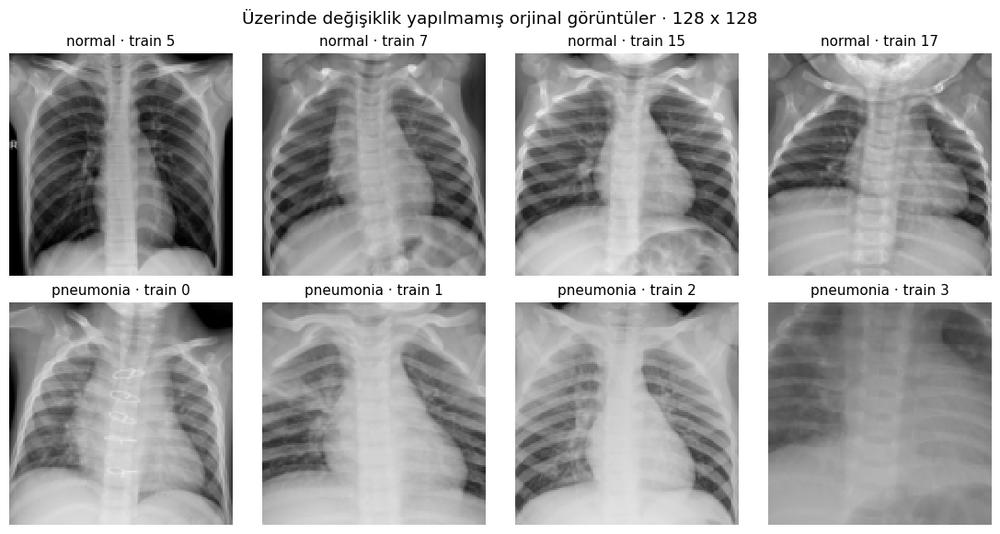

Training histogramları:   0%|          | 0/2 [00:00<?, ?class/s]

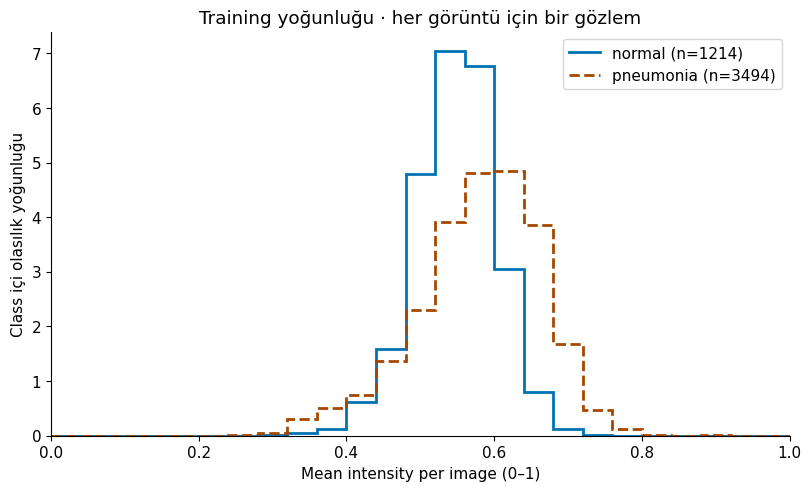

,class_id,n_images,mean_of_image_means,sd_of_image_means_ddof1
0,0,1214,0.548178,0.054342
1,1,3494,0.579826,0.083556


In [ ]:
# study-cell: exploratory-data-analysis
figure_records = []
pending_figures = []
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'pdf.fonttype': 42,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white'})

def save_figure(fig, name, description):
    if 'code_sha256' not in runtime:
        pending_figures.append((fig, name, description))
        plt.show()
        plt.close(fig)
        return
    paths = []
    for extension in ('png', 'pdf'):
        destination = FIGURES / f'{name}.{extension}'
        fig.savefig(destination, dpi=180, facecolor='white')
        paths.append(str(destination.relative_to(ROOT)))
    figure_records.append({'name': name, 'paths': paths, 'description': description,
                           'config_sha256': runtime['config_sha256'],
                           'data_sha256': data_provenance['sha256']})
    plt.show()
    plt.close(fig)

train_images = datasets['train'].imgs
train_labels = np.asarray(datasets['train'].labels).reshape(-1)
example_count = cfg['exploratory-data-analysis']['examples_per_class']
example_indices = {label: np.flatnonzero(train_labels == label)[:example_count].tolist()
                   for label in (0, 1)}
fig, axes = plt.subplots(2, example_count, figsize=(11, 5.7), layout='constrained', squeeze=False)
for label in progress((0, 1), desc='A5 training examples', unit='class'):
    for column, index in enumerate(example_indices[label]):
        ax = axes[label, column]
        ax.imshow(train_images[index] / 255.0, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(f'{label_names[label]} · train {index}', fontsize=11)
        ax.axis('off')
fig.suptitle('Üzerinde değişiklik yapılmamış orjinal görüntüler · 128 x 128')
save_figure(fig, 'training_examples', 'Her sınıf için bir satır; sabit bir kurala göre seçilmiş eğitim görüntüleri; ortak [0, 1] gri ton ölçeği.')

image_means = train_images.mean(axis=(1, 2), dtype=np.float64) / 255.0
intensity_bins = np.linspace(0, 1, cfg['exploratory-data-analysis']['intensity_histogram_bins'] + 1)
fig, ax = plt.subplots(figsize=(8, 4.8), layout='constrained')
intensity_summaries = []
for label, color, style in progress([(0, '#0072B2', '-'), (1, '#A64700', '--')],
                                   desc='Training histogramları', unit='class'):
    values = image_means[train_labels == label]
    density, _ = np.histogram(values, bins=intensity_bins, density=True)
    assert np.isclose(np.sum(density * np.diff(intensity_bins)), 1.0)
    ax.stairs(density, intensity_bins, label=f'{label_names[label]} (n={len(values)})',
              color=color, linestyle=style, linewidth=2)
    intensity_summaries.append({'class_id': label, 'n_images': len(values),
                                'mean_of_image_means': float(values.mean()),
                                'sd_of_image_means_ddof1': float(values.std(ddof=1)),
                                'histogram_density': density.tolist()})
ax.set(xlim=(0, 1), ylim=(0, None), xlabel='Mean intensity per image (0–1)',
       ylabel='Class içi olasılık yoğunluğu', title='Training yoğunluğu · her görüntü için bir gözlem')
ax.legend()
save_figure(fig, 'training_intensity', 'Her görüntünün ortalama piksel yoğunluğunu gösteren, Class-normalized histogram; ortak ve sabit aralıklar kullanılmıştır, test görüntüleri dahil edilmemiştir.')
display(pd.DataFrame([{k: v for k, v in record.items() if k != 'histogram_density'}
                      for record in intensity_summaries]))


## Eşleştirilmiş İnputların Hazırlanması

Normalizasyon inputun nümerik ölçeğini değiştirmektedir. CNN ortalama 0.5 ve standart sapma olarak 0.5 kullanır. Resnet-18'e aynı görüntünün üç kopyasını üç farklı kanaldan girişi yapılır ve ImageNet normalizasyonu kullanır.

Veri artırma, görüntüleri en fazla 5° döndürerek ve %2 kaydırarak eğitim verisinde küçük değişiklikler oluşturur; görüntüleri aynalama uygulanmaz. Baseline training verisi bozulmalar içermemektedir. validation ve test splitlerinde bulunan değişiklikler sabittir ki evaluation aşamasında farklılıklar oluşmasın. Gürültü, bulanıklık veya kontrast değişiklikleri, normalizasyondan önce [0, 1] aralığındaki gri ton değerlerine uygulanır. Evaluation için yapılan değişiklikler orjinal görüntü ID'leri ve corruption seedleri ile eşleştirilmitir.


In [7]:
# study-cell: inputs
weight_preprocessing = ResNet18_Weights[cfg['models']['resnet18']['weights']].transforms()
assert np.allclose(weight_preprocessing.mean, cfg['models']['resnet18']['normalization']['mean'])
assert np.allclose(weight_preprocessing.std, cfg['models']['resnet18']['normalization']['std'])

augmentation = transforms.RandomAffine(
    degrees=cfg['augmentation']['affine_degrees'],
    translate=cfg['augmentation']['affine_translate'],
    interpolation=InterpolationMode[cfg['augmentation']['interpolation'].upper()], fill=cfg['augmentation']['fill'])

conditions = [('clean', 0, 0.0)]
for family, parameters in [('noise', cfg['corruptions']['noise']['std']),
                           ('blur', cfg['corruptions']['blur']['sigma']),
                           ('contrast', cfg['corruptions']['contrast']['factors'])]:
    conditions.extend((family, severity, value) for severity, value in enumerate(parameters, 1))
assert len(conditions) == 10 and len(set(conditions)) == 10

def corrupt_image(image, split, index, condition):
    family, severity, value = condition
    if family == 'clean':
        return image.clone()
    if family == 'noise':
        identity = f"{cfg['seeds']['corruption']}:{split}:{int(index)}".encode()
        key = int.from_bytes(hashlib.blake2b(identity, digest_size=8).digest(), 'little')
        generator = torch.Generator(device='cpu').manual_seed(key)
        field = torch.randn(image.shape, generator=generator, dtype=image.dtype)
        return (image + value * field).clamp(0, 1)
    if family == 'blur':
        return TF.gaussian_blur(image, cfg['corruptions']['blur']['kernel_size'], sigma=[value, value])
    if family == 'contrast':
        return TF.adjust_contrast(image, value)
    raise ValueError(f'Unknown condition: {condition}')

def training_quality_augmentation(image):
    policy = cfg['robustness']['policy']
    probabilities = torch.tensor(policy['probabilities'], dtype=torch.float32)
    family = policy['families'][int(torch.multinomial(probabilities, 1).item())]
    if family == 'clean':
        return image
    low, high = policy[f'{family}_range']
    value = float(torch.empty(()).uniform_(low, high))
    if family == 'noise':
        return (image + value * torch.randn_like(image)).clamp(0, 1)
    if family == 'blur':
        return TF.gaussian_blur(image, cfg['corruptions']['blur']['kernel_size'], sigma=[value, value])
    if family == 'contrast':
        return TF.adjust_contrast(image, value)
    raise ValueError(f'Unknown training family: {family}')

def prepare_image(image, model_name, training=False):
    if training:
        image = augmentation(image)
        if ROBUST:
            assert model_name == 'resnet18', 'Sadece validation-selected ResNet robust olarak eğitilmiştir.'
            image = training_quality_augmentation(image)
    if model_name == 'resnet18':
        image = image.repeat(3, 1, 1)
    normalization = cfg['models'][model_name]['normalization']
    return TF.normalize(image, normalization['mean'], normalization['std'])

class ImageDataset(Dataset):
    def __init__(self, split, model_name, indices, training=False, condition=('clean', 0, 0.0)):
        if split not in {'train', 'val'} and not (split == 'test' and MODE == 'full' and TEST_GATE):
            raise ValueError('A sadece training ve validation yükleyicilerini destekler; final test inference için daha sonra protokol dondurulması gerekir.')
        if training and (split != 'train' or condition[0] != 'clean'):
            raise ValueError('Baseline augmentation sadece training sırasında uygulanır ve kalite bozulmaları içermez.')
        self.split, self.model_name = split, model_name
        self.indices = np.asarray(indices, dtype=np.int64)
        self.training, self.condition = training, condition

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        index = int(self.indices[position])
        image = torch.from_numpy(datasets[self.split].imgs[index].copy()).unsqueeze(0).float() / 255.0
        image = corrupt_image(image, self.split, index, self.condition)
        image = prepare_image(image, self.model_name, training=self.training)
        label = float(datasets[self.split].labels[index, 0])
        return image, torch.tensor(label, dtype=torch.float32), index

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def split_indices(split):
    assert split in {'train', 'val'} or (split == 'test' and MODE == 'full' and TEST_GATE)
    indices = np.arange(len(datasets[split]))
    if MODE == 'smoke':
        from sklearn.model_selection import train_test_split
        count = cfg['execution']['smoke'][f'{split}_samples']
        indices, _ = train_test_split(indices, train_size=count,
                                      stratify=datasets[split].labels.reshape(-1),
                                      random_state=cfg['execution']['smoke']['subset_seed'])
    return np.sort(indices)

def make_loader(split, model_name, seed, training=False, condition=('clean', 0, 0.0)):
    dataset = ImageDataset(split, model_name, split_indices(split), training, condition)
    batch_size = cfg['execution']['smoke']['batch_size'] if MODE == 'smoke' else cfg['training']['batch_size']
    return DataLoader(dataset, batch_size=batch_size, shuffle=training,
                      num_workers=cfg['execution']['num_workers'], worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(seed),
                      pin_memory=device.type == 'cuda', drop_last=False)


In [8]:
# study-cell: input-checks
check_started = time.perf_counter()
checks = {}
sample_index = int(example_indices[0][0])
sample = torch.from_numpy(train_images[sample_index].copy()).unsqueeze(0).float() / 255
assert sample.shape == (1, 128, 128) and 0 <= sample.min() <= sample.max() <= 1
checks['label_mapping_shape_dtype_range'] = True
for model_name, channels in [('cnn', 1), ('resnet18', 3)]:
    prepared = prepare_image(sample, model_name)
    assert prepared.shape == (channels, 128, 128) and torch.isfinite(prepared).all()
    normalization = cfg['models'][model_name]['normalization']
    means = torch.tensor(normalization['mean'])[:, None, None]
    stds = torch.tensor(normalization['std'])[:, None, None]
    assert torch.allclose(prepared * stds + means, sample.expand(channels, -1, -1), atol=1e-6)
    first = next(iter(make_loader('val', model_name, cfg['seeds']['primary'])))
    second = next(iter(make_loader('val', model_name, cfg['seeds']['primary'])))
    assert torch.equal(first[0], second[0]) and torch.equal(first[2], second[2])
    assert set(first[1].tolist()).issubset({0., 1.})
    checks[f'{model_name}_preprocessing_and_validation_repeatability'] = True

seed_all(cfg['seeds']['primary'])
training_check_model = 'resnet18' if ROBUST else 'cnn'
augmented_first = next(iter(make_loader('train', training_check_model, cfg['seeds']['primary'], training=True)))
seed_all(cfg['seeds']['primary'])
augmented_second = next(iter(make_loader('train', training_check_model, cfg['seeds']['primary'], training=True)))
assert torch.equal(augmented_first[0], augmented_second[0])
assert torch.equal(augmented_first[2], augmented_second[2])
checks['seeded_training_loader_and_augmentation'] = True

corruption_hashes = {}
for condition in progress(conditions, desc='A7 corruption checks', unit='condition'):
    corrupted = corrupt_image(sample, 'train', sample_index, condition)
    seed_all(123)  # unrelated global training RNG changes must not alter corruptions
    repeated = corrupt_image(sample, 'train', sample_index, condition)
    assert torch.equal(corrupted, repeated)
    assert torch.isfinite(corrupted).all() and 0 <= corrupted.min() <= corrupted.max() <= 1
    corruption_hashes[str(condition)] = hashlib.sha256(corrupted.numpy().tobytes()).hexdigest()
checks['all_ten_conditions_finite_bounded_repeatable'] = True


midgray = torch.full_like(sample, 0.5)
small = corrupt_image(midgray, 'train', sample_index, ('noise', 1, cfg['corruptions']['noise']['std'][0]))
medium = corrupt_image(midgray, 'train', sample_index, ('noise', 2, cfg['corruptions']['noise']['std'][1]))
unclipped = (small > 0) & (small < 1) & (medium > 0) & (medium < 1)
assert torch.allclose((small[unclipped] - .5) / cfg['corruptions']['noise']['std'][0],
                      (medium[unclipped] - .5) / cfg['corruptions']['noise']['std'][1], atol=3e-6)
different_identity = corrupt_image(sample, 'train', sample_index + 1, conditions[1])
assert not torch.equal(corrupt_image(sample, 'train', sample_index, conditions[1]), different_identity)
checks['paired_noise_field_and_sample_identity'] = True

noise_dataset = ImageDataset('train', 'cnn', list(range(4)), condition=conditions[1])
forward = {noise_dataset[i][2]: noise_dataset[i][0] for i in range(4)}
reverse = {noise_dataset[i][2]: noise_dataset[i][0] for i in reversed(range(4))}
assert all(torch.equal(forward[index], reverse[index]) for index in forward)
checks['corruption_access_order_independence'] = True
if sys.platform.startswith('linux'):
    serial = list(DataLoader(noise_dataset, batch_size=2, num_workers=0))
    parallel = list(DataLoader(noise_dataset, batch_size=2, num_workers=2,
                               multiprocessing_context='fork', worker_init_fn=seed_worker))
    assert all(torch.equal(a[0], b[0]) and torch.equal(a[2], b[2]) for a, b in zip(serial, parallel))
    checks['two_worker_corruption_invariance'] = True
else:
    checks['two_worker_corruption_invariance'] = 'İşlem çalıştırılamadı: Colab/Linux üzerinde yeniden deneyin'

contrast_value = cfg['corruptions']['contrast']['factors'][-1]
observed_contrast = corrupt_image(sample, 'train', sample_index, ('contrast', 3, contrast_value))
expected_contrast = contrast_value * sample + (1 - contrast_value) * sample.mean()
assert torch.allclose(observed_contrast, expected_contrast, atol=1e-6)
checks['contrast_is_mean_centered_not_brightness_scaling'] = True
checks['check_seconds'] = time.perf_counter() - check_started


display(pd.DataFrame({'check': list(checks), 'result': list(checks.values())}))


A7 corruption checks:   0%|          | 0/10 [00:00<?, ?condition/s]

,check,result
0,label_mapping_shape_dtype_range,True
1,cnn_preprocessing_and_validation_repeatability,True
2,resnet18_preprocessing_and_validation_repeatab...,True
3,seeded_training_loader_and_augmentation,True
4,all_ten_conditions_finite_bounded_repeatable,True
5,paired_noise_field_and_sample_identity,True
6,corruption_access_order_independence,True
7,two_worker_corruption_invariance,True
8,contrast_is_mean_centered_not_brightness_scaling,True
9,check_seconds,0.975516


## İki model arası karşılaştırma

Basit CNN modelimiz 23.473 adet parametre içerirken, Resnet18 11.177.025 adet parametre içermektedir ve önceden eğitilmiş hazır bir modeldir. Resnet üzerine fine-tuning yapılmıştır.

İki model de çıktı oalrak logit denen raw skorlar verir. Training binary cross-entropy loss ve AdamW kullanmaktadır. BatchNorm aktif olarak training esnasında istatistiklerini kendi kendine güncellemektedir ve kaydetmektedir.

In [9]:
# study-cell: models
import copy
from urllib.parse import urlparse
from scipy.special import expit
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             f1_score)
from torchvision.models import resnet18
from torch import nn

RUN_B = True

def validate_b_contract():
    expected = {
        'loss': 'BCEWithLogitsLoss', 'class_weighting': 'none', 'optimizer': 'AdamW',
        'checkpoint_rule': 'highest_clean_val_auroc_then_earliest_epoch',
        'architecture_selection': 'primary_seed_clean_val_auroc_only',
        'architecture_tie_preference': 'cnn', 'mixed_precision': False,
    }
    for key, value in expected.items():
        assert cfg['training'][key] == value, f'Unsupported training choice: {key}'
    assert cfg['training']['early_stopping']['monitor'] == 'clean_val_auroc'
    assert cfg['training']['early_stopping']['min_delta'] == 0.0
    assert cfg['training']['early_stopping']['patience'] >= 1
    assert cfg['training']['max_epochs'] >= 1 and cfg['execution']['smoke']['max_epochs'] >= 1
    assert cfg['models']['cnn']['block'] == 'conv3_bn_relu_maxpool2'
    assert cfg['models']['cnn']['pooling'] == 'adaptive_average'
    assert len(cfg['models']['cnn']['channels']) == 3
    assert cfg['models']['resnet18']['fine_tuning'] == 'all_parameters'
    assert cfg['models']['resnet18']['batchnorm_policy'] == 'train_running_stats_in_training_eval_stats_in_validation'
    assert cfg['models']['resnet18']['weights'] == 'IMAGENET1K_V1'
    assert cfg['models']['resnet18']['input_channels'] == 3
    assert cfg['models']['resnet18']['output_logits'] == 1
    assert cfg['dataset']['official_splits'] == ['train', 'val', 'test']
    assert cfg['threshold']['method'] == 'youden_j'
    assert cfg['threshold']['split'] == 'val' and cfg['threshold']['condition'] == 'clean'
    assert cfg['threshold']['candidates'] == 'unique_validation_logits_mapped_to_probabilities_plus_zero_and_one'
    assert cfg['threshold']['comparison'] == 'probability_greater_than_or_equal'
    assert cfg['threshold']['tie_rule'] == 'largest_threshold_within_tolerance'
    assert cfg['metrics']['auprc'] == 'average_precision'
    assert cfg['metrics']['class_order'] == [0, 1]
    assert cfg['metrics']['f1_zero_division'] == 0
    assert cfg['metrics']['undefined_rates'] == 'nan'
    assert cfg['metrics']['seed_sd_ddof'] == 1

class CompactCNN(nn.Module):
    def __init__(self):
        super().__init__()
        blocks, channels = [], 1
        for width in cfg['models']['cnn']['channels']:
            blocks.extend([nn.Conv2d(channels, width, 3, padding=1, bias=False),
                           nn.BatchNorm2d(width), nn.ReLU(), nn.MaxPool2d(2)])
            channels = width
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(cfg['models']['cnn']['dropout']),
                                  nn.Linear(channels, 1))

    def forward(self, images):
        return self.head(self.pool(self.features(images)))

def build_model(name, initialize_pretrained=True):
    if name == 'cnn':
        return CompactCNN(), {'initialization': 'scratch'}
    if name != 'resnet18':
        raise ValueError(f'Unknown architecture: {name}')
    weights = ResNet18_Weights[cfg['models'][name]['weights']]
    if initialize_pretrained:
        torch.hub.set_dir(str(local_path(cfg['paths']['checkpoints']) / 'imagenet_cache'))
        state = weights.get_state_dict(progress=True, check_hash=True)
        cached = Path(torch.hub.get_dir()) / 'checkpoints' / Path(urlparse(weights.url).path).name
        cached_sha256 = file_hash(cached)
        official_hash_prefix = cached.stem.rsplit('-', 1)[1]
        assert cached_sha256.startswith(official_hash_prefix), 'Resmi ImageNet checksum ile eşleşmiyor.'
        model = resnet18(weights=None)
        model.load_state_dict(state, strict=True)
        provenance = {'initialization': 'official_imagenet', 'weights': weights.name,
                      'url': weights.url, 'file_sha256': cached_sha256,
                      'official_hash_prefix_verified': official_hash_prefix}
        del state
    else:
        model, provenance = resnet18(weights=None), {'initialization': 'trained_checkpoint_reload'}
    model.fc = nn.Linear(model.fc.in_features, cfg['models'][name]['output_logits'])
    assert all(parameter.requires_grad for parameter in model.parameters())
    return model, provenance

def make_optimizer(model, name):
    if name == 'cnn':
        groups = [{'params': model.parameters(), 'lr': cfg['training']['learning_rate_cnn']}]
    else:
        groups = [
            {'params': [p for key, p in model.named_parameters() if not key.startswith('fc.')],
             'lr': cfg['training']['learning_rate_resnet_backbone']},
            {'params': model.fc.parameters(), 'lr': cfg['training']['learning_rate_resnet_head']},
        ]
    return torch.optim.AdamW(groups, weight_decay=cfg['training']['weight_decay'])

if RUN_B:
    validate_b_contract()


## Skorlar ve threshold seçimi

AUROC ve AUPRC modelin sınıfları ne kadar iyi sıraladığını gösterir. Burada AUPRC, average
precision olarak hesaplanır. Sensitivity zatürreli görüntülerin, specificity ise normal
görüntülerin ne kadarının doğru bulunduğunu gösterir. F1, precision ve sensitivity'yi
birleştirir; balanced accuracy ise sensitivity ve specificity'nin ortalamasıdır.

Threshold sadece temiz validation üzerinde Youden's J ile seçilir ve tüm test koşullarında
sabit tutulur. Eşit skorlarda daha büyük threshold seçilir. Kaggle temiz test sonuçlarında
ResNet42, CNN42'den altı metrikte de daha iyidir; AUROC değerleri 0.9833 ve 0.9537'dir.
ResNet için üç seedin ortalaması ve standart sapması raporlanır, test sonucuna göre seed
seçilmez. Bu standart sapma trainingler arasındaki farkı gösterir, güven aralığı değildir.


In [10]:
# study-cell: metrics
def checked_scores(labels, logits):
    labels = np.asarray(labels).reshape(-1)
    logits = np.asarray(logits, dtype=np.float64).reshape(-1)
    assert labels.size == logits.size and labels.size > 0
    assert set(np.unique(labels)).issubset({0, 1}) and np.isfinite(logits).all()
    return labels.astype(np.int64), logits

def cutoff_value(rule):
    if rule['kind'] == 'endpoint_zero':
        return -np.inf
    if rule['kind'] == 'endpoint_one':
        return np.inf
    assert rule['kind'] == 'observed_logit' and np.isfinite(rule['logit_cutoff'])
    return float(rule['logit_cutoff'])

def decision_labels(logits, rule, temperature=1.0):
    logits = np.asarray(logits, dtype=np.float64)
    assert np.isfinite(logits).all() and np.isfinite(temperature) and temperature > 0
    # Preserve canonical raw decisions even if scaled float64 neighbors coalesce.
    return (logits >= cutoff_value(rule)).astype(np.int64)

def check_mapped_decisions(logits, rule, temperature):
    raw = decision_labels(logits, rule, temperature)
    mapped = (np.asarray(logits, dtype=np.float64) / temperature >= cutoff_value(rule) / temperature)
    assert np.array_equal(raw, mapped), 'Dönüştürülen threshold’da sayısal hassasiyet kaybı oluştu; raw skorlara göre verilen orijinal sınıf kararlarını koru.'
    return True

def choose_threshold(labels, logits):
    labels, logits = checked_scores(labels, logits)
    assert set(np.unique(labels)) == {0, 1}, 'Youden J iki validation classına ihtiyaç duyuyor.'
    cuts = np.r_[-np.inf, np.unique(logits), np.inf]
    js = []
    for cut in cuts:
        predicted = logits >= cut
        js.append(float(predicted[labels == 1].mean() - predicted[labels == 0].mean()))
    js = np.asarray(js)
    chosen = np.flatnonzero(js >= js.max() - cfg['threshold']['tie_tolerance'])[-1]
    cut = cuts[chosen]
    kind = 'endpoint_zero' if np.isneginf(cut) else 'endpoint_one' if np.isposinf(cut) else 'observed_logit'
    return {'kind': kind, 'logit_cutoff': float(cut) if np.isfinite(cut) else None,
            'probability_threshold': float(expit(cut)), 'youden_j': float(js[chosen]),
            'candidate_count': len(cuts), 'fit_split': 'val', 'fit_condition': 'clean',
            'comparison': 'greater_than_or_equal', 'canonical_space': 'logit'}

def binary_metrics(labels, logits, rule):
    labels, logits = checked_scores(labels, logits)
    predicted = decision_labels(logits, rule)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel().tolist()
    sensitivity = tp / (tp + fn) if tp + fn else float('nan')
    specificity = tn / (tn + fp) if tn + fp else float('nan')
    both = len(np.unique(labels)) == 2
    return {'auroc': float(roc_auc_score(labels, logits)) if both else float('nan'),
            'average_precision': float(average_precision_score(labels, logits)) if both else float('nan'),
            'f1': float(f1_score(labels, predicted, zero_division=cfg['metrics']['f1_zero_division'])),
            'sensitivity': sensitivity, 'specificity': specificity,
            'balanced_accuracy': float((sensitivity + specificity) / 2),
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp, 'sample_count': labels.size}

def better_epoch(score, best):
    return score > best  # Exact ties retain the earliest epoch.

def select_architecture(primary_validation_scores):
    assert set(primary_validation_scores) == {'cnn', 'resnet18'}
    assert np.isfinite(list(primary_validation_scores.values())).all()
    return ('resnet18' if primary_validation_scores['resnet18'] >
            primary_validation_scores['cnn'] + cfg['training']['tie_tolerance'] else 'cnn')

def metric_invariant_checks():
    y, z = np.array([0, 1, 0, 1]), np.array([-2., -1., 1., 2.])
    rule = {'kind': 'observed_logit', 'logit_cutoff': 0.0}
    measured = binary_metrics(y, z, rule)
    for key, value in {'auroc': .75, 'average_precision': 5/6, 'f1': .5,
                       'sensitivity': .5, 'specificity': .5, 'balanced_accuracy': .5,
                       'tn': 1, 'fp': 1, 'fn': 1, 'tp': 1}.items():
        assert np.isclose(measured[key], value), (key, measured[key], value)
    tied = choose_threshold([0, 1], [0., 0.])
    assert tied['kind'] == 'endpoint_one'  # J=0 everywhere; highest candidate wins.
    for values in [np.array([-1000., -900., 900., 1000.]), z, np.array([-1., -1., 1., 1.])]:
        rules = [choose_threshold(y, values),
                 {'kind': 'endpoint_zero', 'logit_cutoff': None},
                 {'kind': 'endpoint_one', 'logit_cutoff': None}]
        rules += [{'kind': 'observed_logit', 'logit_cutoff': float(c)} for c in np.unique(values)]
        for boundary in rules:
            for temperature in cfg['calibration']['temperature_bounds'] + [1.0]:
                assert np.array_equal(decision_labels(values, boundary),
                                      decision_labels(values, boundary, temperature))
                assert check_mapped_decisions(values, boundary, temperature)
                assert roc_auc_score(y, values) == roc_auc_score(y, values / temperature)
                assert average_precision_score(y, values) == average_precision_score(y, values / temperature)
    saturated = choose_threshold([0, 1], [900., 1000.])
    assert saturated['kind'] == 'observed_logit' and saturated['logit_cutoff'] == 1000.
    assert saturated['probability_threshold'] == 1.0
    assert decision_labels([900., 1000.], saturated).tolist() == [0, 1]
    neighbors = np.array([1.3000000000000005, 1.3000000000000007])
    neighbor_rule = {'kind': 'observed_logit', 'logit_cutoff': float(neighbors[1])}
    assert decision_labels(neighbors, neighbor_rule, 20.).tolist() == [0, 1]
    try:
        check_mapped_decisions(neighbors, neighbor_rule, 20.)
    except AssertionError:
        pass
    else:
        raise AssertionError('Precision-collapse diagnostic did not trigger.')
    undefined = binary_metrics([0, 0], [-1., 1.], rule)
    assert np.isnan(undefined['sensitivity']) and np.isnan(undefined['balanced_accuracy'])
    assert not better_epoch(.8, .8) and better_epoch(.81, .8)
    assert select_architecture({'cnn': .8, 'resnet18': .8}) == 'cnn'
    assert select_architecture({'cnn': .8, 'resnet18': .81}) == 'resnet18'
    return {'hand_calculated_metrics': True, 'threshold_ties_endpoints_saturation': True,
            'temperature_decision_and_ranking_invariants': True,
            'undefined_rates': True, 'checkpoint_architecture_ties': True}

if RUN_B:
    b_checks = metric_invariant_checks()


## Training ve checkpoint seçimi

`full_learning_curves` her training için bir satır gösterir. X ekseni epoch, soldaki grafikler
loss, sağdakiler AUROC değerleridir. Training lossun düşmesi tek başına modelin yeni
verilerde daha iyi olduğunu göstermez. Training sırasında veri artırma da uygulanır.

En yüksek clean-validation AUROC skoruna sahip checkpoint kaydedilir; eşitlikte önceki
epoch seçilir. Bu yüzden en iyi model son epochtaki model olmayabilir. Tamamlanmış
checkpointler ancak kod, ayarlar, ortam ve dosya kontrolleri eşleşirse tekrar kullanılır.
Kaydedilen ağırlıklar yarım kalan traininge devam etmek için optimizer durumunu içermez.


In [11]:
# study-cell: training
def synchronize_device():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()

def run_epoch(model, loader, optimizer=None):
    assert loader.dataset.split in {'train', 'val', 'test'}
    if loader.dataset.split == 'test':
        assert MODE == 'full' and TEST_GATE and optimizer is None, 'Test inference için eğitim ve validation protokolü tamamlanmış olmalıdır.'
    training = optimizer is not None
    assert not training or loader.dataset.split == 'train'
    assert training or not loader.dataset.training
    model.train(training)
    total_loss, labels_out, logits_out, indices_out = 0., [], [], []
    phase = 'train' if training else f'{loader.dataset.split} {loader.dataset.condition[0]}'
    with progress(loader, desc=f'{model.__class__.__name__} {phase}', unit='batch', leave=False) as batches:
        for images, labels, indices in batches:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                outputs = model(images)
                assert outputs.shape == (len(labels), 1)
                logits = outputs.squeeze(1)
                assert torch.isfinite(logits).all()
                loss = nn.functional.binary_cross_entropy_with_logits(logits, labels)
                assert torch.isfinite(loss)
                if training:
                    loss.backward()
                    assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())
                    optimizer.step()
            total_loss += float(loss.detach().cpu()) * len(labels)
            labels_out.append(labels.detach().cpu().numpy())
            logits_out.append(logits.detach().cpu().numpy())
            indices_out.append(indices.numpy())
            batches.set_postfix(loss=f'{total_loss / sum(len(y) for y in labels_out):.4f}', refresh=False)
    labels, logits = checked_scores(np.concatenate(labels_out), np.concatenate(logits_out))
    indices = np.concatenate(indices_out)
    order = np.argsort(indices)
    assert len(set(indices.tolist())) == len(loader.dataset)
    return {'loss': total_loss / len(labels), 'auroc': float(roc_auc_score(labels, logits)),
            'labels': labels[order], 'logits': logits[order], 'indices': indices[order]}

def training_recipe(config):
    recipe = copy.deepcopy(config)
    for control in ['reuse_completed_checkpoints', 'progress', 'auto_download_colab_backups']:
        recipe['execution'].pop(control, None)
    return recipe

def recipe_hash(recipe):
    return hashlib.sha256(json.dumps(recipe, sort_keys=True).encode()).hexdigest()

def run_identity(name, seed):
    return {'model': name, 'seed': seed, 'mode': MODE, 'recipe': ACTIVE_RECIPE,
            'recipe_sha256': recipe_hash(training_recipe(cfg)),
            'code_sha256': runtime['code_sha256'], 'data_sha256': data_provenance['sha256'],
            'packages': runtime['packages'], 'device': runtime['device']}

def run_files(name, seed):
    key = f'{name}_seed{seed}'
    directory = local_path(cfg['paths']['checkpoints']) / ARTIFACT_MODE / key
    artifacts = OUTPUT / 'b' / key
    cache = local_path(cfg['paths']['prediction_cache']) / ARTIFACT_MODE / 'b'
    return {'checkpoint': directory / 'best.pt', 'metadata': artifacts / 'completed.json',
            'history': artifacts / 'history.csv', 'validation': cache / f'{key}_validation.npz'}

def save_tensor_state(path, model):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.partial')
    torch.save({k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, temporary)
    temporary.replace(path)

def load_trained_model(name, path):
    model, _ = build_model(name, initialize_pretrained=False)
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True), strict=True)
    return model.to(device).eval()

def train_or_reuse(name, seed):
    identity, files = run_identity(name, seed), run_files(name, seed)
    if any(path.exists() for path in files.values()):
        if not cfg['execution']['reuse_completed_checkpoints']:
            raise FileExistsError(f'{name}/{seed} için kayıtlı dosyalar var; doğrulama sonrası tekrar kullanımı etkinleştir, mevcut dosyaların üzerine yazma.')
        assert all(path.is_file() for path in files.values()), 'Tamamlanamamış bir run; kurtarmadan önce inceleyin.'
        metadata = json.loads(files['metadata'].read_text())
        assert metadata['identity'] == identity and metadata['completed'] is True, 'İdentity uyuşmazlığı çalıştır.'
        tqdm.write(f'{MODE} {name} seed={seed}: tamamlanan checkpoint\'ı yeniden kullanıyor; eğitim yapılmıyor.')
        for key in ['checkpoint', 'history', 'validation']:
            assert file_hash(files[key]) == metadata['file_sha256'][key], f'{key} checksum uyuşmazlığı'
        model = load_trained_model(name, files['checkpoint'])
        return model, metadata, pd.read_csv(files['history']), True
    seed_all(seed)
    synchronize_device()
    started = time.perf_counter()
    model, initialization = build_model(name)
    model = model.to(device)
    optimizer = make_optimizer(model, name)
    train_loader = make_loader('train', name, seed, training=True)
    val_loader = make_loader('val', name, seed)
    epochs = cfg['execution']['smoke']['max_epochs'] if MODE == 'smoke' else cfg['training']['max_epochs']
    history, best, bad_epochs = [], -np.inf, 0
    best_epoch = None
    initial_bn = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()
                  if key.endswith('num_batches_tracked')}
    with progress(range(1, epochs + 1), desc=f'{name} seed={seed} epochs', unit='epoch') as epoch_bar:
        for epoch in epoch_bar:
            synchronize_device()
            epoch_started = time.perf_counter()
            train = run_epoch(model, train_loader, optimizer)
            validation = run_epoch(model, val_loader)
            synchronize_device()
            row = {'mode': MODE, 'model': name, 'seed': seed, 'epoch': epoch,
                   'train_loss': train['loss'], 'train_online_augmented_auroc': train['auroc'],
                   'clean_val_loss': validation['loss'], 'clean_val_auroc': validation['auroc'],
                   'epoch_seconds': time.perf_counter() - epoch_started}
            history.append(row)
            epoch_bar.set_postfix(train_loss=f'{train["loss"]:.4f}', val_loss=f'{validation["loss"]:.4f}',
                                  val_auroc=f'{validation["auroc"]:.4f}', refresh=False)
            if better_epoch(validation['auroc'], best):
                best, best_epoch, bad_epochs = validation['auroc'], epoch, 0
                save_tensor_state(files['checkpoint'], model)
                best_predictions = {key: validation[key].copy() for key in ['labels', 'logits', 'indices']}
            else:
                bad_epochs += 1
            tqdm.write(f'{MODE} {name} seed={seed} epoch={epoch}: val AUROC={validation["auroc"]:.4f}')
            if bad_epochs >= cfg['training']['early_stopping']['patience']:
                break
    assert all(int(model.state_dict()[key].detach().cpu()) > int(value) for key, value in initial_bn.items())
    trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    learning_rates = [group['lr'] for group in optimizer.param_groups]
    del optimizer, model
    model = load_trained_model(name, files['checkpoint'])
    before_eval = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    reloaded = run_epoch(model, val_loader)
    assert all(torch.equal(value.detach().cpu(), before_eval[key]) for key, value in model.state_dict().items())
    assert np.array_equal(reloaded['indices'], best_predictions['indices'])
    assert np.array_equal(reloaded['labels'], best_predictions['labels'])
    assert np.allclose(reloaded['logits'], best_predictions['logits'], rtol=1e-5, atol=1e-6)
    assert reloaded['auroc'] == best, 'Checkpoint reload changed selection AUROC.'
    threshold = choose_threshold(reloaded['labels'], reloaded['logits'])
    assert threshold == choose_threshold(best_predictions['labels'], best_predictions['logits'])
    assert np.array_equal(decision_labels(reloaded['logits'], threshold),
                          decision_labels(best_predictions['logits'], threshold))
    metrics = binary_metrics(reloaded['labels'], reloaded['logits'], threshold)
    synchronize_device()
    elapsed = time.perf_counter() - started
    for path in files.values():
        path.parent.mkdir(parents=True, exist_ok=True)
    history = pd.DataFrame(history)
    history.to_csv(files['history'], index=False)
    np.savez_compressed(files['validation'], **{k: reloaded[k] for k in ['labels', 'logits', 'indices']})
    metadata = {
        'completed': True, 'identity': identity, 'config_sha256': runtime['config_sha256'],
        'observed_config': copy.deepcopy(cfg), 'initialization': initialization,
        'trainable_parameters': trainable_parameters, 'optimizer_group_learning_rates': learning_rates,
        'best_epoch': best_epoch, 'best_clean_val_auroc': best,
        'epochs_executed': len(history), 'stop_reason': 'early_stopping' if bad_epochs >= cfg['training']['early_stopping']['patience'] else 'epoch_budget',
        'train_indices': split_indices('train').tolist(), 'validation_indices': reloaded['indices'].tolist(),
        'threshold': threshold, 'clean_validation_metrics': metrics,
        'elapsed_seconds_including_initialization_reload': elapsed,
        'checkpoint_kind': 'completed_best_model_not_optimizer_resume',
        'reload_max_absolute_logit_difference': float(np.max(np.abs(reloaded['logits'] - best_predictions['logits']))),
        'batchnorm_training_updates_and_eval_immutability': True,
        'files': {k: str(v.relative_to(ROOT)) for k, v in files.items()},
        'file_sha256': {k: file_hash(files[k]) for k in ['checkpoint', 'history', 'validation']},
        'test_inference': False, 'scientific_selection_eligible': MODE == 'full',
    }
    write_json(files['metadata'], metadata)
    return model, metadata, history, False


## Görüntü kalitesinin değerlendirilmesi

Temiz görüntülere ek olarak gürültü SD 0.03/0.07/0.12, bulanıklık sigma 0.5/1/2 ve kontrast
0.8/0.6/0.4 koşulları değerlendirilir. Bozulmalar ayrı uygulanır; kontrast katsayısı
küçüldükçe görüntü daha fazla bozulur.

`c_corruption_examples` aynı görüntünün temiz ve bozulmuş hallerini gösterir.
`full_severity` satırlarda metrikleri, sütunlarda bozulmaları gösterir. X ekseni bozulma
seviyesi, y ekseni metrik değeridir. İnce çizgiler seedleri, siyah çizgi ortalama ± standart
sapmayı gösterir.

Kaggle baseline sonuçlarında en büyük AUROC kaybı gürültü 0.12'de görülmüştür. Tüm görüntüler
zatürre tahmin edildiği için sensitivity 1, specificity 0 olmuştur. Thresholdlar sabittir;
bozulma şiddetleri aileler arasında eşdeğer değildir. Görüntü ID'leri, labellar ve logitler
`.npz`, metrikler `results.csv` dosyalarında saklanır. Smoke sadece validation kullanır.


In [12]:
# study-cell: corruptions
from scipy.optimize import minimize_scalar

def condition_key(condition):
    family, severity, _ = condition
    return f'{family}_{severity}'

def analysis_provenance(record):
    return {'mode': MODE, 'model': record['identity']['model'], 'seed': record['identity']['seed'],
            'data_sha256': data_provenance['sha256'],
            'checkpoint_sha256': record['file_sha256']['checkpoint'],
            'checkpoint_source_sha256': record['identity']['code_sha256'],
            'consumer_source_sha256': runtime['code_sha256'],
            'consumer_config_sha256': runtime['config_sha256']}

def input_digest(split, name, indices, condition):

    digest = hashlib.sha256()
    dataset = ImageDataset(split, name, indices, condition=condition)
    for image, label, index in dataset:
        digest.update(np.asarray([index], dtype='<i8').tobytes())
        digest.update(image.contiguous().numpy().tobytes())
    return digest.hexdigest()

def predict_condition(model, record, split, condition):

    assert split in {'train', 'val'} or (split == 'test' and MODE == 'full' and TEST_GATE), 'Final test inference is gated.'
    assert not model.training
    name, seed = record['identity']['model'], record['identity']['seed']
    indices = split_indices(split)
    key = f'{name}_seed{seed}_{split}_{condition_key(condition)}'
    directory = local_path(cfg['paths']['prediction_cache']) / ARTIFACT_MODE / 'c'
    directory.mkdir(parents=True, exist_ok=True)
    path, manifest = directory / f'{key}.npz', directory / f'{key}.json'
    identity = {**analysis_provenance(record), 'split': split, 'condition': list(condition),
                'indices': indices.tolist(), 'input_sha256': input_digest(split, name, indices, condition)}
    if path.exists() or manifest.exists():
        assert path.is_file() and manifest.is_file(), 'Tamamlanamamış bir öngörü cache; kurtarmadan önce inceleyin.'
        saved = json.loads(manifest.read_text())
        assert saved['identity'] == identity, 'Öngörü cache identity uyuşmazlığı.'
        assert file_hash(path) == saved['sha256'], 'Öngörü cache checksum uyuşmazlığı.'
        with np.load(path, allow_pickle=False) as cache:
            prediction = {k: cache[k].copy() for k in ['indices', 'labels', 'logits']}
        reused = True
    else:
        state_before = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        prediction = run_epoch(model, make_loader(split, name, seed, condition=condition))
        assert all(torch.equal(v.detach().cpu(), state_before[k]) for k, v in model.state_dict().items())
        prediction = {k: prediction[k] for k in ['indices', 'labels', 'logits']}
        temporary = path.with_suffix('.partial.npz')
        np.savez_compressed(temporary, **prediction)
        temporary.replace(path)
        write_json(manifest, {'identity': identity, 'sha256': file_hash(path)})
        reused = False
    labels, logits = checked_scores(prediction['labels'], prediction['logits'])
    assert np.array_equal(prediction['indices'], indices)
    assert np.array_equal(labels, np.asarray(datasets[split].labels).reshape(-1)[indices])
    return {**prediction, 'labels': labels, 'logits': logits, 'condition': condition,
            'split': split, 'cache': str(path.relative_to(ROOT)), 'cache_sha256': file_hash(path),
            'input_sha256': identity['input_sha256'], 'reused': reused}

def paired_drop_table(frame):
    identifiers = ['mode', 'model', 'seed', 'split', 'calibration', 'metric']
    clean = frame[frame.family == 'clean'][identifiers + ['value']].rename(columns={'value': 'clean_value'})
    result = frame[frame.family != 'clean'].merge(clean, on=identifiers, validate='many_to_one')
    result['clean_minus_corrupted'] = result['clean_value'] - result['value']
    return result

def discrimination_rows(record, cache):
    family, severity, parameter = cache['condition']
    metrics = binary_metrics(cache['labels'], cache['logits'], record['threshold'])
    return [{**analysis_provenance(record), 'split': cache['split'], 'family': family,
             'severity': severity, 'parameter': parameter, 'calibration': 'raw',
             'sample_count': len(cache['labels']), 'metric': metric, 'value': float(value),
             'cache': cache['cache'], 'cache_sha256': cache['cache_sha256']}
            for metric, value in metrics.items() if metric != 'sample_count']

def plot_corruption_examples(split, index):
    raw = torch.from_numpy(datasets[split].imgs[index].copy()).float()[None] / 255.
    fig, axes = plt.subplots(3, 4, figsize=(11, 8), layout='constrained')
    for row, family in enumerate(['noise', 'blur', 'contrast']):
        selected = [conditions[0]] + [c for c in conditions if c[0] == family]
        for ax, condition in zip(axes[row], selected):
            image = corrupt_image(raw, split, index, condition)
            ax.imshow(image[0], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            ax.set_title('Clean' if condition[0] == 'clean' else f'{family} = {condition[2]:g}')
            ax.axis('off')
    fig.suptitle(f'{MODE.upper()} · {split} index {index} · identical image, grayscale limits [0,1]')
    save_figure(fig, 'c_corruption_examples', f'{split} splitinde ve {index} indexinde deterministik bozulmalar eşleştirildi: şiddeti soldan sağa gittikçe artmakta.')

def plot_discrimination(frame):
    metrics = ['auroc', 'f1', 'sensitivity', 'specificity']
    fig, axes = plt.subplots(4, 3, figsize=(12, 11), layout='constrained', sharey=True)
    families = ['noise', 'blur', 'contrast']
    for col, family in enumerate(families):
        selected_conditions = [conditions[0]] + [c for c in conditions if c[0] == family]
        for row, metric in enumerate(metrics):
            ax = axes[row, col]
            for name, color, marker in [('cnn', '#0072B2', 'o'), ('resnet18', '#A64700', 's')]:
                values = []
                for condition in selected_conditions:
                    values.append(frame[(frame.model == name) & (frame.metric == metric) &
                                        (frame.family == condition[0]) & (frame.severity == condition[1])].value.item())
                ax.plot(range(4), values, marker=marker, color=color, label=name)
            ax.set(ylim=(0, 1.03), xticks=range(4),
                   xticklabels=['clean'] + [f'{c[2]:g}' for c in selected_conditions[1:]])
            ax.set_ylabel(metric.replace('_', ' '))
            if row == 0:
                ax.set_title(f'{family} · worsening →')
            if row == 3:
                ax.set_xlabel('Corruption parametreleri ayarlandı')
            ax.grid(alpha=.2)
    axes[0, 0].legend(fontsize=9)
    fig.suptitle(f'{MODE.upper()} · Sadece validation · seed 42 · debugging, bilimsel bir karşılaştırma değildir')
    save_figure(fig, 'c_discrimination', 'İki smoke checkpointi; clean-validation thresholdları düzeltildi.')


## Güven skorları ve temperature scaling

NLL yüksek güvenle yapılan hataları, Brier olasılıkların karesel hatasını ölçer. ECE,
15 eşit aralıktaki ortalama olasılık ile gerçek zatürre oranını karşılaştırır ve görüntü
sayılarına göre ağırlıklandırır. Üçünde de düşük değer daha iyidir.

Her checkpoint için T sadece temiz validation NLL üzerinden öğrenilir ve tüm test
koşullarında aynı tutulur: `p = sigmoid(logit / T)`. Threshold da dönüştürüldüğü için sınıf
kararları değişmez. AUROC ve average precision da aynı kalır.

Reliability grafiklerinde solda ham, sağda ölçeklenmiş olasılıklar bulunur. X ekseni tahmin
olasılığı, y ekseni gerçek zatürre oranıdır. Köşegene yakınlık uyumu gösterir; az görüntü
bulunan aralıklar daha değişkendir. Kaggle baseline'da temiz NLL artarken dayanıklı modelde
azalmıştır. ECE ise her koşulda iyileşmemiştir; kalibrasyonun her zaman fayda sağlaması beklenmez.


In [13]:
# study-cell: calibration
def reliability_bins(labels, probabilities):
    labels = np.asarray(labels).reshape(-1)
    probabilities = np.asarray(probabilities, dtype=np.float64).reshape(-1)
    assert labels.size == probabilities.size and labels.size > 0
    assert set(np.unique(labels)).issubset({0, 1})
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    assert cfg['calibration']['ece_convention'] == 'positive_class_equal_width'
    assert cfg['calibration']['ece_bins'] == 15
    edges = np.linspace(0., 1., cfg['calibration']['ece_bins'] + 1)
    membership = np.searchsorted(edges, probabilities, side='right') - 1
    membership = np.minimum(membership, len(edges) - 2)
    records = []
    for i in range(len(edges) - 1):
        mask = membership == i
        count = int(mask.sum())
        records.append({'bin': i, 'left': float(edges[i]), 'right': float(edges[i + 1]),
                        'count': count,
                        'mean_probability': float(probabilities[mask].mean()) if count else np.nan,
                        'positive_frequency': float(labels[mask].mean()) if count else np.nan})
    result = pd.DataFrame(records)
    assert result['count'].sum() == len(labels)
    return result

def calibration_metrics(labels, logits, temperature=1.):
    labels, logits = checked_scores(labels, logits)
    assert np.isfinite(temperature) and temperature > 0
    scaled = logits / temperature
    assert np.isfinite(scaled).all()
    probabilities = expit(scaled)
    nll = np.logaddexp(0., np.where(labels == 1, -scaled, scaled)).mean()
    bins = reliability_bins(labels, probabilities)
    populated = bins[bins['count'] > 0]
    ece = np.sum(populated['count'] / len(labels) *
                 np.abs(populated.mean_probability - populated.positive_frequency))
    return {'nll': float(nll), 'brier': float(np.mean((probabilities - labels) ** 2)), 'ece': float(ece)}

def fit_temperature(labels, logits, *, split, condition):
    assert split == 'val' and tuple(condition) == ('clean', 0, 0.0), 'Temperature fitting clean-validation-only.'
    labels, logits = checked_scores(labels, logits)
    assert set(np.unique(labels)) == {0, 1}
    options = cfg['calibration']
    assert options['method'] == 'temperature_scaling' and options['objective'] == 'unweighted_binary_nll'
    assert options['fit_split'] == 'val' and options['fit_condition'] == 'clean'
    assert options['optimizer'] == 'bounded_scalar_log_temperature'
    lower, upper = options['temperature_bounds']
    assert 0 < lower < 1 < upper
    evaluations = []
    def objective(log_temperature):
        temperature = float(np.exp(log_temperature))
        scaled = logits / temperature
        value = float(np.logaddexp(0., np.where(labels == 1, -scaled, scaled)).mean())
        assert np.isfinite(value)
        evaluations.append({'temperature': temperature, 'nll': value})
        return value
    bounds = np.log([lower, upper])
    result = minimize_scalar(objective, method='bounded', bounds=tuple(bounds),
                             options={'xatol': options['optimizer_xatol']})
    if not result.success or not np.isfinite(result.fun):
        raise RuntimeError(f'Temperature optimizasyonu başarısız: {result.message}')
    # Explicitly evaluate both finite bounds and T=1; no silent worse-than-identity fit.
    candidates = [float(result.x), float(bounds[0]), 0., float(bounds[1])]
    values = [objective(x) for x in candidates]
    best_index = int(np.argmin(values))
    temperature = [float(np.exp(result.x)), float(lower), 1., float(upper)][best_index]
    before = calibration_metrics(labels, logits, 1.)['nll']
    numerical_tie_tolerance = float(64 * np.finfo(np.float64).eps * max(1., abs(before)))
    no_improvement = before - min(values) <= numerical_tie_tolerance
    if no_improvement:
        temperature, best_index = 1., 2
    after = calibration_metrics(labels, logits, temperature)['nll']
    assert after <= before + 1e-12
    boundary = (temperature in [lower, upper] or
                min(abs(np.log(temperature) - bounds)) <= max(1e-6, 10 * options['optimizer_xatol']))
    return {'temperature': temperature, 'fit_split': split, 'fit_condition': 'clean',
            'optimizer_success': bool(result.success), 'optimizer_message': str(result.message),
            'optimizer_nfev': int(result.nfev), 'objective_evaluations': len(evaluations),
            'raw_optimizer_temperature': float(np.exp(result.x)),
            'bounds': [lower, upper], 'boundary_hit': bool(boundary),
            'selected_candidate': ['optimizer', 'lower_bound', 'identity', 'upper_bound'][best_index],
            'nll_before': before, 'nll_after': after,
            'identity_tie_tolerance': numerical_tie_tolerance,
            'no_numerical_improvement': bool(no_improvement),
            'flat_candidate_objective': bool(np.ptp(values) <= numerical_tie_tolerance),
            'validation_performance_is_independent': False, 'evaluations': evaluations}

def calibrated_rows(record, cache, fit):
    temperature, rule = fit['temperature'], record['threshold']
    labels, logits = checked_scores(cache['labels'], cache['logits'])
    check_mapped_decisions(logits, rule, temperature)  # Actual fitted T, on EVERY cache.
    assert np.array_equal(decision_labels(logits, rule), decision_labels(logits, rule, temperature))
    assert roc_auc_score(labels, logits) == roc_auc_score(labels, logits / temperature)
    assert average_precision_score(labels, logits) == average_precision_score(labels, logits / temperature)
    family, severity, parameter = cache['condition']
    rows = []
    for state, value in [('raw', 1.), ('temperature_scaled', temperature)]:
        for metric, score in calibration_metrics(labels, logits, value).items():
            rows.append({**analysis_provenance(record), 'split': cache['split'], 'family': family,
                         'severity': severity, 'parameter': parameter, 'calibration': state,
                         'sample_count': len(labels), 'metric': metric, 'value': score,
                         'temperature': value, 'raw_probability_threshold': rule['probability_threshold'],
                         'mapped_probability_threshold': float(expit(cutoff_value(rule) / value)),
                         'canonical_logit_cutoff': rule['logit_cutoff'], 'threshold_kind': rule['kind'],
                         'cache': cache['cache'], 'cache_sha256': cache['cache_sha256']})
    return rows

def calibration_checks():
    scores = calibration_metrics([0, 1], [0., 0.])
    assert np.isclose(scores['nll'], np.log(2.)) and scores['brier'] == .25 and scores['ece'] == 0.
    edges = np.linspace(0., 1., cfg['calibration']['ece_bins'] + 1)
    bins = reliability_bins([0, 1, 1], [0., edges[1], 1.])
    assert bins.iloc[0]['count'] == 1 and bins.iloc[1]['count'] == 1 and bins.iloc[-1]['count'] == 1
    assert bins['count'].sum() == 3 and bins.loc[bins['count'] == 0, 'mean_probability'].isna().all()
    assert calibration_metrics([0, 1], [-1000., 1000.])['nll'] == 0.
    fit = fit_temperature([0, 1, 0, 1], [-1., 1., -2., 2.], split='val', condition=conditions[0])
    assert fit['boundary_hit'] and fit['temperature'] == cfg['calibration']['temperature_bounds'][0]
    flat = fit_temperature([0, 1], [0., 0.], split='val', condition=conditions[0])
    assert np.isclose(flat['nll_after'], np.log(2.))
    assert flat['temperature'] == 1. and flat['flat_candidate_objective'] and not flat['boundary_hit']
    for split, condition in [('train', conditions[0]), ('val', conditions[1])]:
        try:
            fit_temperature([0, 1], [-1., 1.], split=split, condition=condition)
        except AssertionError:
            pass
        else:
            raise AssertionError('Non-clean-validation temperature fit kabul edildi')
    return {'hand_calculated_nll_brier_ece': True, 'bin_edges_endpoints_empty_bins': True,
            'stable_extreme_logits': True, 'bounded_optimizer_and_boundary_diagnostic': True,
            'fit_split_condition_guard': True}

def plot_reliability(record, caches, fit):
    source_tables = []
    for page, start in enumerate(range(0, len(caches), 5), 1):
        selected = caches[start:start + 5]
        fig, axes = plt.subplots(len(selected), 2, figsize=(10, 3.1 * len(selected)),
                                 layout='constrained', squeeze=False)
        for row, cache in enumerate(selected):
            for col, (state, temperature, color, marker) in enumerate([
                    ('raw', 1., '#0072B2', 'o'),
                    ('temperature_scaled', fit['temperature'], '#A64700', 's')]):
                bins = reliability_bins(cache['labels'], expit(cache['logits'] / temperature))
                source_tables.append(bins.assign(condition=condition_key(cache['condition']), calibration=state))
                ax = axes[row, col]
                ax.plot([0, 1], [0, 1], linestyle='--', color='#666666', linewidth=1)
                filled = bins[bins['count'] > 0]
                ax.scatter(filled.mean_probability, filled.positive_frequency, marker=marker, color=color, s=35, clip_on=False)
                ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean pneumonia probability', ylabel='Observed positive fraction',
                       title=f'{condition_key(cache["condition"])} · {state} · T={temperature:.3g}')
                counts = ', '.join(str(v) for v in bins['count'])
                ax.text(.5, -.32, f'Bin counts, left → right: {counts}', transform=ax.transAxes,
                        ha='center', fontsize=8)
                ax.grid(alpha=.15)
        fig.suptitle(f'{MODE.upper()} · {record["identity"]["model"]} seed 42 · {selected[0]["split"]}\n'
                     'T sadece temiz validation üzerinden öğrenildi; az görüntü içeren aralıklarda hesaplanan oranlar daha değişken olabilir.', fontsize=12)
        save_figure(fig, f'd_reliability_{record["identity"]["model"]}_{page}',
                    'Pozitif sınıf için reliability grafiği; 15 eşit genişlikte aralık ve ortak 0–1 eksen ölçekleri kullanılmıştır. Veriler birleştirilmemiştir ve gösterilen split açıkça belirtilmiştir.')
    table = pd.concat(source_tables, ignore_index=True)
    table.to_csv(OUTPUT / 'd' / f'{record["identity"]["model"]}_seed42_reliability_bins.csv', index=False)
    return table


## E. Grad-CAM karşılaştırması

Grad-CAM, `layer4[-1].conv2` üzerinden raw zatürre skoruna pozitif katkı veren bölgeleri
gösterir. Orijinal harita 4 × 4'tür ve 128 × 128'e büyütülür. Grafiklerde her satır bir
görüntü, sütunlar temiz/gürültü 0.12/bulanıklık 2/kontrast 0.4 koşullarıdır. Label ve raw
olasılık da gösterilir. Renk ölçeği sadece aynı görüntünün panelleri arasında ortaktır.

Kaggle sonuçlarında test ID'si 3 olan görüntü temizken doğru normal, gürültü eklendiğinde
ise yanlış zatürre tahmin edilmiştir. Yani vurgulanan bir bölge tahminin doğru olduğunu
göstermez. Sıfır harita da hastalık olmadığı anlamına gelmez.

TP/TN/FP/FN gruplarından ID sırasıyla üçer görüntü seçilerek 48 harita üretilmiştir.
Haritalar kabadır; lezyonun yerini doğrulamaz veya klinik geçerlilik kanıtlamaz. Kaydedilmiş
skorlarla eşleşmek için aynı inference batchleri kullanılır, model durumu güncellenmez.


In [14]:
# study-cell: gradcam
def select_explanation_groups(clean_cache, rule):
    predicted = decision_labels(clean_cache['logits'], rule)
    labels, indices = clean_cache['labels'], clean_cache['indices']
    masks = {'TP': (labels == 1) & (predicted == 1), 'TN': (labels == 0) & (predicted == 0),
             'FP': (labels == 0) & (predicted == 1), 'FN': (labels == 1) & (predicted == 0)}
    count = cfg['gradcam']['examples_per_group'] if MODE == 'full' else 1
    assert cfg['gradcam']['selection'] == 'ascending_official_test_index'
    return {group: {'available': int(mask.sum()), 'selected_indices': np.sort(indices[mask])[:count].tolist(),
                    'shortfall': max(0, count - int(mask.sum()))} for group, mask in masks.items()}

def paired_gradcam(model, record, caches, *, replay_quantitative_batch=True):
    from captum.attr import LayerGradCam, LayerAttribution
    assert cfg['gradcam']['target'] == 'raw_pneumonia_logit' and cfg['gradcam']['positive_attributions']
    assert cfg['gradcam']['layer'] == 'layer4[-1].conv2'
    assert cfg['gradcam']['shared_scale'] == 'within_image_across_four_conditions'
    model.eval()
    state_before = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    clean = caches[0]
    assert clean['condition'] == conditions[0] and (clean['split'] in {'train', 'val'} or (MODE == 'full' and TEST_GATE and clean['split'] == 'test'))
    selected_conditions = [conditions[0]] + [c for c in conditions if c[1] == 3]
    assert len(selected_conditions) == 4
    groups = select_explanation_groups(clean, record['threshold'])
    cam = LayerGradCam(model, model.layer4[-1].conv2)
    explanation_records = []
    attribution_stage = 'e_batch_replay' if replay_quantitative_batch else 'e'
    directory = local_path(cfg['paths']['prediction_cache']) / ARTIFACT_MODE / attribution_stage
    directory.mkdir(parents=True, exist_ok=True)
    for group in progress(cfg['gradcam']['groups'], desc='E paired Grad-CAM', unit='group'):
        indices = groups[group]['selected_indices']
        if not indices:
            continue
        fig, axes = plt.subplots(len(indices), 4, figsize=(12, 3.1 * len(indices)),
                                 layout='constrained', squeeze=False)
        for row, index in enumerate(indices):
            raw = torch.from_numpy(datasets[clean['split']].imgs[index].copy()).float()[None] / 255.
            label = int(datasets[clean['split']].labels[index, 0])
            panels = []
            for condition in selected_conditions:
                corrupted = corrupt_image(raw, clean['split'], index, condition)
                image = prepare_image(corrupted, 'resnet18')[None].to(device).requires_grad_(True)
                batch_indices, batch_position = [int(index)], 0
                attribution_input = image
                if replay_quantitative_batch:
                    for batch_images, _, batch_ids in make_loader(clean['split'], 'resnet18', 42, condition=condition):
                        batch_indices = batch_ids.tolist()
                        if int(index) in batch_indices:
                            break
                    assert int(index) in batch_indices
                    batch_position = batch_indices.index(int(index))
                    assert torch.equal(batch_images[batch_position], image.detach().cpu()[0])
                    attribution_input = batch_images.to(device).requires_grad_(True)
                model.zero_grad(set_to_none=True)
                with torch.enable_grad():
                    native_batch = cam.attribute(attribution_input, target=0, relu_attributions=True)
                    native = native_batch[batch_position:batch_position + 1]
                    expanded = LayerAttribution.interpolate(native, (128, 128), interpolate_mode='bilinear')
                assert native.shape == (1, 1, 4, 4) and expanded.shape == (1, 1, 128, 128)
                heatmap = expanded.detach().cpu().numpy()[0, 0]
                assert np.isfinite(heatmap).all() and (heatmap >= 0).all()
                cached = next(c for c in caches if c['condition'] == condition)
                position = int(np.flatnonzero(cached['indices'] == index).item())
                logit = float(cached['logits'][position])
                with torch.no_grad():
                    single_logit = float(model(attribution_input)[batch_position, 0].cpu())
                assert np.isclose(single_logit, logit, rtol=1e-4, atol=1e-5), 'Grad-CAM tahmini sayısal cache ile uyuşmuyor.'
                predicted = int(decision_labels([logit], record['threshold'])[0])
                panels.append({'image': corrupted[0].numpy(), 'heatmap': heatmap,
                               'native': native.detach().cpu().numpy(), 'condition': condition,
                               'attribution_batch_indices': batch_indices,
                               'prediction_replay_logit': single_logit, 'cached_logit': logit,
                               'raw_probability': float(expit(logit)), 'predicted': predicted,
                               'cache': cached['cache'], 'cache_sha256': cached['cache_sha256'],
                               'input_tensor_sha256': hashlib.sha256(image.detach().cpu().numpy().tobytes()).hexdigest()})
            shared_max = max(float(panel['heatmap'].max()) for panel in panels)
            for col, panel in enumerate(panels):
                ax = axes[row, col]
                scaled = panel['heatmap'] / shared_max if shared_max > 0 else np.zeros_like(panel['heatmap'])
                ax.imshow(panel['image'], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
                overlay = ax.imshow(scaled, cmap='magma', vmin=0, vmax=1, alpha=cfg['gradcam']['opacity'])
                zero_note = ' · zero map' if not panel['heatmap'].any() else ''
                ax.set_title(f'{condition_key(panel["condition"])}{zero_note}\n'
                             f'{clean["split"]} {index}: true={label}, pred={panel["predicted"]}\n'
                             f'Raw pneumonia p={panel["raw_probability"]:.3f}', fontsize=10)
                ax.axis('off')
                path = directory / f'resnet18_seed42_{clean["split"]}_{index}_{condition_key(panel["condition"])}.npz'
                np.savez_compressed(path, native=panel['native'], expanded=panel['heatmap'])
                explanation_records.append({**analysis_provenance(record), 'split': clean['split'],
                    'group_from_clean_prediction': group, 'official_index': index, 'true_label': label,
                    'predicted_label': panel['predicted'], 'raw_probability': panel['raw_probability'],
                    'condition': list(panel['condition']), 'target': 'raw_pneumonia_logit',
                    'native_shape': [1, 1, 4, 4], 'expanded_shape': [1, 1, 128, 128],
                    'all_zero_map': not bool(panel['heatmap'].any()), 'within_image_shared_max': shared_max,
                    'quantitative_cache': panel['cache'], 'quantitative_cache_sha256': panel['cache_sha256'],
                    'input_tensor_sha256': panel['input_tensor_sha256'],
                    'attribution_batch_indices': panel['attribution_batch_indices'],
                    'prediction_replay_logit': panel['prediction_replay_logit'],
                    'cached_logit': panel['cached_logit'],
                    'attribution_cache': str(path.relative_to(ROOT)), 'attribution_sha256': file_hash(path)})
            fig.colorbar(overlay, ax=axes[row].tolist(), shrink=.7,
                         label='Göreli pozitif katkı\n(ölçek yalnızca bu görüntü içinde ortaktır)')
        fig.suptitle(f'{MODE.upper()} · {clean["split"]} · clean group {group} · '
                     f'shown {len(indices)}/{groups[group]["available"]} available\n'
                     'Raw zatürre logiti; orijinal 4×4 harita interpolasyonla 128×128’e büyütülmüştür. Nitel bir gösterimdir, hastalığın yerini belirlediği iddia edilmez.', fontsize=11)
        save_figure(fig,f'{attribution_stage}_gradcam_{group}',f'Sabit kuralla seçilen {clean["split"]} örnekleri; temiz ve en yüksek seviyede bozulmuş görüntüler; her görüntü için ortak ölçek; raw olasılıklar.')
    model.zero_grad(set_to_none=True)
    assert all(torch.equal(v.detach().cpu(), state_before[k]) for k, v in model.state_dict().items())
    expected = sum(len(g['selected_indices']) for g in groups.values()) * 4
    assert len(explanation_records) == expected
    return {'groups': groups, 'records': explanation_records, 'eval_state_unchanged': True,
            'target': 'raw_pneumonia_logit', 'split': clean['split'],
            'replay_quantitative_batch': replay_quantitative_batch, 'test_inference': clean['split'] == 'test'}


## Dayanıklılık karşılaştırması ve kayıt

Dayanıklı modelde affine veri artırmadan sonra temiz, gürültü, bulanıklık veya kontrast
koşullarından biri eşit olasılıkla seçilir. Rastgele aralıklar sırasıyla gürültü [0,0.12],
bulanıklık [0.5,2], kontrast [0.4,1]'dir. Aynı üç seed ve maksimum training bütçesi kullanılır.
Checkpoint, threshold ve T seçimleri temiz validation üzerinden yapılır.

`robustness_vs_baseline` grafiğinde mavi kesikli çizgiler baseline, turuncu düz çizgiler
dayanıklı modeldir. Değerler ortalama ± seed standart sapmasıdır. Aynı evaluation görüntüleri
kullanılır; farklar aynı seed içinde hesaplanır ve baseline tahminleri tekrar kullanılır.

Kaggle'da dayanıklı modelin AUROC değeri tüm koşullarda artmıştır. Ancak temiz F1 ve
specificity düşmüştür; yani her metrik iyileşmemiştir. Bu yöntem baseline test sonuçlarından
sonra geliştirildiği için keşifseldir, Colab tekrarı da bağımsız doğrulama sayılmaz.

Checkpoint ZIP'leri ağırlık ve validation kayıtlarını, sonuç ZIP'i grafik, CSV ve tahmin
cachelerini saklar. YAML ayar kopyası da dahil edilir. Colab geçici olduğu için dosyaların
bilgisayara indirildiği kontrol edilmelidir; dayanıklılık ZIP'i yalnızca o karşılaştırma çalışırsa oluşur.


In [15]:
# study-cell: exports
def plot_full_learning(histories):
    fig, axes = plt.subplots(len(histories), 2, figsize=(11, 3 * len(histories)), layout='constrained', squeeze=False)
    for row, history in enumerate(histories):
        key = f'{history.model.iloc[0]} seed {history.seed.iloc[0]}'
        axes[row, 0].plot(history.epoch, history.train_loss, '-o', label='Train, online/augmented')
        axes[row, 0].plot(history.epoch, history.clean_val_loss, '--s', label='Clean validation')
        axes[row, 1].plot(history.epoch, history.train_online_augmented_auroc, '-o', label='Train, online/augmented')
        axes[row, 1].plot(history.epoch, history.clean_val_auroc, '--s', label='Clean validation')
        for ax, ylabel in zip(axes[row], ['Unweighted binary loss', 'AUROC']):
            ax.set(xlabel='Epoch', ylabel=ylabel, title=key)
            ax.legend(fontsize=8)
            ax.grid(alpha=.2)
        axes[row, 1].set_ylim(0, 1.03)
    recipe_label = 'robust augmentation' if ROBUST else 'baseline'
    fig.suptitle(f'{MODE.upper()} {recipe_label} eğitim geçmişi · training AUROC, veri artırma uygulanırken ve ağırlıklar güncellenirken hesaplanır')
    save_figure(fig, 'full_learning_curves', f'{len(histories)} {recipe_label} eğitim kaydı; veri artırma ile hesaplanan training metrikleri, temiz validation metriklerinden ayrı gösterilir.')

def full_results_table(c_frame, d_frame, selected, expected_runs=4):

    keys = ['mode', 'model', 'seed', 'split', 'family', 'severity', 'parameter', 'sample_count']
    base = c_frame.copy()
    mapping = d_frame[keys + ['calibration', 'temperature', 'mapped_probability_threshold',
                              'canonical_logit_cutoff', 'threshold_kind']].drop_duplicates()
    base = base.drop(columns='calibration').merge(mapping, on=keys, validate='many_to_many')
    combined = pd.concat([base, d_frame], ignore_index=True)
    combined = combined.rename(columns={'mode': 'run_mode', 'family': 'corruption_family',
        'severity': 'severity_index', 'parameter': 'parameter_value', 'calibration': 'calibration_status',
        'mapped_probability_threshold': 'decision_threshold'})
    combined['statistic'] = 'individual'
    combined['seed'] = combined.seed.astype(str)
    group_keys = ['run_mode', 'model', 'split', 'corruption_family', 'severity_index', 'parameter_value',
                  'calibration_status', 'sample_count', 'metric']
    selected_rows = combined[combined.model == selected]
    assert set(selected_rows.seed) == {'42', '123', '2026'}
    grouped = selected_rows.groupby(group_keys, dropna=False)['value']
    assert (grouped.count() == 3).all(), 'Full modda üç seedin özet sonuçları hesaplanırken eksik veya tanımsız bir metrik bulundu.'
    aggregates = []
    for statistic, values in [('mean', grouped.mean()), ('standard_deviation', grouped.std(ddof=1))]:
        table = values.reset_index()
        table['statistic'], table['seed'] = statistic, 'aggregate_42_123_2026'
        table['decision_threshold'], table['temperature'] = np.nan, np.nan
        aggregates.append(table)
    combined = pd.concat([combined, *aggregates], ignore_index=True)
    unique = group_keys + ['seed', 'statistic']
    assert not combined.duplicated(unique).any()
    expected_individual = expected_runs * 10 * 2 * 13
    assert (combined.statistic == 'individual').sum() == expected_individual
    columns = ['run_mode', 'model', 'seed', 'split', 'corruption_family', 'severity_index', 'parameter_value',
               'calibration_status', 'decision_threshold', 'temperature', 'sample_count', 'metric', 'value', 'statistic',
               'threshold_kind', 'canonical_logit_cutoff', 'cache', 'cache_sha256',
               'checkpoint_sha256', 'checkpoint_source_sha256', 'consumer_source_sha256', 'consumer_config_sha256']
    return combined[columns]

def plot_full_severity(results, selected):
    fig, axes = plt.subplots(4, 3, figsize=(12, 11), layout='constrained', sharey=True)
    metrics = ['auroc', 'f1', 'sensitivity', 'specificity']
    displayed = results[(results.model == selected) & (results.calibration_status == 'raw') & results.metric.isin(metrics) & results.statistic.isin(['mean', 'standard_deviation'])]
    summary_grid = displayed.pivot(index=['metric', 'corruption_family', 'severity_index'], columns='statistic', values='value')
    shared_limits = (min(-.03, float((summary_grid['mean'] - summary_grid['standard_deviation']).min()) - .02),
                     max(1.03, float((summary_grid['mean'] + summary_grid['standard_deviation']).max()) + .02))
    axes[0, 0].set_ylim(*shared_limits)
    for col, family in enumerate(['noise', 'blur', 'contrast']):
        sequence = [conditions[0]] + [c for c in conditions if c[0] == family]
        for row, metric in enumerate(metrics):
            ax = axes[row, col]
            subset = results[(results.model == selected) & (results.metric == metric) &
                             (results.calibration_status == 'raw')]
            for seed in ['42', '123', '2026']:
                values = [subset[(subset.seed == seed) & (subset.corruption_family == c[0]) &
                                 (subset.severity_index == c[1])].value.item() for c in sequence]
                ax.plot(range(4), values, alpha=.45, linewidth=1, marker='.', label=f'seed {seed}')
            summaries = []
            for statistic in ['mean', 'standard_deviation']:
                summaries.append([subset[(subset.statistic == statistic) & (subset.corruption_family == c[0]) &
                                         (subset.severity_index == c[1])].value.item() for c in sequence])
            ax.errorbar(range(4), summaries[0], yerr=summaries[1], fmt='ks-', capsize=3,
                        label='Mean ± sample SD')
            ax.set(xticks=range(4), xticklabels=['clean'] + [f'{c[2]:g}' for c in sequence[1:]],
                   ylabel=metric.replace('_', ' '))
            if row == 0:
                ax.set_title(f'{family} · worsening →')
            if row == 3:
                ax.set_xlabel('Configured corruption parameter')
            ax.grid(alpha=.2)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{selected} · test · temiz validation üzerinden belirlenen sabit karar eşikleri\n'
                 'Üç training seedi; SD hasta bazındaki belirsizliği veya güven aralığını göstermez')
    save_figure(fig, 'full_severity', 'Seçilen mimarinin ayrı seed sonuçları ve ortalama ± örneklem standart sapması; koşullar görüntü bazında eşleştirilmiştir; raw ve kalibre edilmiş tahminlerde sınıf kararları aynıdır.')

def plot_robustness_comparison(baseline, results):
    metrics = ['auroc', 'f1', 'sensitivity', 'specificity']
    limits = [0., 1.]
    for frame in [baseline, results]:
        subset = frame[(frame.statistic == 'individual') & frame.metric.isin(metrics) & (frame.calibration_status == 'raw')]
        grouped = subset.groupby(['metric', 'corruption_family', 'severity_index']).value
        means, sds = grouped.mean(), grouped.std(ddof=1)
        assert (grouped.count() == 3).all() and np.isfinite(sds).all()
        limits.extend([float((means - sds).min()), float((means + sds).max())])
    shared_limits = (min(-.03, min(limits) - .02), max(1.03, max(limits) + .02))
    fig, axes = plt.subplots(4, 3, figsize=(12, 11), layout='constrained', sharey=True)
    for col, family in enumerate(['noise', 'blur', 'contrast']):
        sequence = [conditions[0]] + [c for c in conditions if c[0] == family]
        for row, metric in enumerate(metrics):
            ax = axes[row, col]
            for frame, label, color, marker, style in [(baseline, 'Baseline', '#0072B2', 'o', '--'),
                         (results, 'Robust augmentation', '#A64700', 's', '-')]:
                subset = frame[(frame.statistic == 'individual') & (frame.metric == metric) & (frame.calibration_status == 'raw')]
                means, sds = [], []
                for condition in sequence:
                    values = subset[(subset.corruption_family == condition[0]) & (subset.severity_index == condition[1])].value
                    assert len(values) == 3
                    means.append(values.mean()); sds.append(values.std(ddof=1))
                ax.errorbar(range(4), means, yerr=sds, color=color, marker=marker, linestyle=style,
                            capsize=3, linewidth=1.5, label=label)
            ax.set(xticks=range(4), xticklabels=['clean'] + [f'{c[2]:g}' for c in sequence[1:]],
                   ylabel=metric.replace('_', ' '), ylim=shared_limits)
            if row == 0: ax.set_title(f'{family}: worsening left to right')
            if row == 3: ax.set_xlabel('Configured corruption parameter')
            ax.grid(alpha=.2)
    axes[0, 0].legend(fontsize=9)
    fig.suptitle('Baseline test sonuçları görüldükten sonra yapılan keşifsel çalışma: eşleşen üç seed ID\nTraining seedleri üzerinden ortalama ± örneklem standart sapması; ayrı temiz validation thresholdları')
    save_figure(fig, 'robustness_vs_baseline', 'Keşifsel, eşleştirilmiş evaluation; üç seedin ortalaması ve örneklem standart sapması gösterilir, hasta bazında güven aralığı değildir. Hata çubukları metrik sınırlarının dışına çıkabilir.')

def smoke_gradcam(model):
    from captum.attr import LayerGradCam, LayerAttribution
    assert cfg['gradcam']['layer'] == 'layer4[-1].conv2'
    assert cfg['gradcam']['target'] == 'raw_pneumonia_logit'
    assert cfg['gradcam']['positive_attributions']
    with progress(desc='B Grad-CAM and export', unit='image', total=1) as stage:
        model.eval()
        index = int(split_indices('train')[0])
        raw = torch.from_numpy(datasets['train'].imgs[index].copy()).float()[None] / 255.
        image = prepare_image(raw, 'resnet18')[None].to(device).requires_grad_(True)
        with torch.enable_grad():
            native = LayerGradCam(model, model.layer4[-1].conv2).attribute(
                image, target=0, relu_attributions=True)
            expanded = LayerAttribution.interpolate(native, (128, 128), interpolate_mode='bilinear')
        assert torch.isfinite(native).all() and (native >= 0).all()
        assert expanded.shape == (1, 1, 128, 128)
        heatmap = expanded.detach().cpu().numpy()[0, 0]
        maximum = float(heatmap.max())
        scaled = heatmap / maximum if maximum > 0 else np.zeros_like(heatmap)
        with torch.no_grad():
            probability = float(torch.sigmoid(model(image))[0, 0].cpu())
        fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout='constrained')
        axes[0].imshow(raw[0], cmap='gray', vmin=0, vmax=1)
        axes[0].set_title(f'Train {index} · {label_names[int(datasets["train"].labels[index, 0])]}')
        axes[1].imshow(raw[0], cmap='gray', vmin=0, vmax=1)
        overlay = axes[1].imshow(scaled, cmap='magma', vmin=0, vmax=1, alpha=cfg['gradcam']['opacity'])
        axes[1].set_title(f'Positive Grad-CAM · raw p={probability:.3f}')
        for ax in axes:
            ax.axis('off')
        fig.colorbar(overlay, ax=axes[1], shrink=.7, label='Relative attribution (single image)')
        fig.suptitle('SMOKE CHECK · training görüntüsü · son açıklama sonucu değildir')
        save_figure(fig, 'smoke_resnet_gradcam', 'Training-only raw-logit Grad-CAM smoke check; per-image scale.')
        model.zero_grad(set_to_none=True)
        stage.update(1)
        return {'split': 'train', 'official_index': index, 'native_shape': list(native.shape),
                'expanded_shape': list(expanded.shape), 'raw_pneumonia_probability': probability,
                'all_zero_map': maximum == 0, 'positive_finite': True, 'target': 'raw_pneumonia_logit'}


In [ ]:
# study-cell: controller
import zipfile

def write_once(path, value):
    path = Path(path)
    value = json.loads(json.dumps(value, allow_nan=False))
    if path.exists():
        assert json.loads(path.read_text()) == value, f'Mevcut kaynak kimliği farklı: {path}. Dosyayı koruyun ve inceleyin.'
    else:
        path.parent.mkdir(parents=True, exist_ok=True)
        write_json(path, value)
    return value

def executed_code_snapshot():
    history = get_ipython().history_manager.input_hist_raw
    snapshot = {}
    for text in history:
        lines = text.splitlines()
        if lines and lines[0].startswith('# study-cell: '):
            snapshot[lines[0].split(': ', 1)[1]] = text.replace('\r\n', '\n').rstrip() + '\n'
    expected = ['requirements-download', 'dependencies', 'configuration', 'runtime', 'data', 'exploratory-data-analysis', 'inputs', 'input-checks', 'models', 'metrics', 'training', 'corruptions', 'calibration', 'gradcam', 'exports', 'controller', 'run']
    assert set(snapshot) == set(expected), 'Tüm notebook hücrelerini yeni bir kernel üzerinde sırayla çalıştırın.'
    payload = json.dumps(snapshot, sort_keys=True).encode()
    return snapshot, hashlib.sha256(payload).hexdigest()

def set_context(recipe):
    global ROBUST, ACTIVE_RECIPE, ARTIFACT_MODE, OUTPUT, FIGURES, figure_records
    ACTIVE_RECIPE = recipe
    ROBUST = recipe == 'robustness_v1'
    ARTIFACT_MODE = Path(recipe) / MODE
    OUTPUT = local_path(cfg['paths']['outputs']) / ARTIFACT_MODE
    FIGURES = OUTPUT / 'figures'
    FIGURES.mkdir(parents=True, exist_ok=True)
    figure_records = []
    write_once(OUTPUT / 'executed_code.json', CODE_SNAPSHOT)

def freeze_recipe():
    assert not TEST_GATE
    validate_b_contract()
    assert checks['all_ten_conditions_finite_bounded_repeatable']
    assert checks['paired_noise_field_and_sample_identity']
    if MODE == 'full':
        assert device.type == 'cuda' and sys.platform.startswith('linux')
        assert checks['two_worker_corruption_invariance'] is True
    freeze = {'code_sha256': runtime['code_sha256'],
              'source_identity_method': 'sha256 of latest executed named code cells, JSON sorted by cell name',
              'configuration': cfg, 'recipe': ACTIVE_RECIPE,
              'data_sha256': data_provenance['sha256'], 'packages': runtime['packages'],
              'device': runtime['device'], 'gpu': runtime['gpu'],
              'historical_benchmark_test_already_exposed': True,
              'interpretation': 'fixed_recipe_reproduction; robustness remains exploratory'}
    record = write_once(OUTPUT / 'protocol_freeze.json', freeze)
    export_configuration(OUTPUT / 'config.yaml')
    return record

def restore_completed_selection():
    selection_path = OUTPUT / 'selection.json'
    if (OUTPUT / 'test_exposure.json').exists():
        assert selection_path.is_file(), 'Test verisi kullanıldıktan sonra orijinal seçim kaydını geri yükleyin; yeniden training başlatmayın.'
    if selection_path.exists():
        previous = json.loads(selection_path.read_text())
        assert previous['protocol_freeze_sha256'] == file_hash(OUTPUT / 'protocol_freeze.json')
        for run in previous['runs']:
            paths = run_files(run['model'], run['seed'])
            assert all(p.is_file() for p in paths.values()), 'Tamamlanmış training dosyalarını geri yükleyin; eksik dosyalar için yeniden training başlatmayın.'
            assert file_hash(paths['checkpoint']) == run['checkpoint_sha256']

def temperature_for(record):
    key = f"{record['identity']['model']}_seed{record['identity']['seed']}"
    path = OUTPUT / 'd' / f'{key}_temperature.json'
    cache_path = local_path(record['files']['validation'])
    assert file_hash(cache_path) == record['file_sha256']['validation']
    provenance = {**analysis_provenance(record), 'clean_validation_cache': record['files']['validation'],
                  'clean_validation_cache_sha256': record['file_sha256']['validation']}
    if path.exists():
        fit = json.loads(path.read_text())
        assert all(fit[k] == v for k, v in provenance.items()), 'Temperature kayıtları kaynak bilgileriyle uyuşmuyor.'
        assert fit['fit_split'] == 'val' and fit['fit_condition'] == 'clean'
    else:
        assert not (OUTPUT / 'test_exposure.json').exists(), 'Test öncesindeki temperature kaydını geri yükleyin; test verisi kullanıldıktan sonra tekrar hesaplamayın.'
        with np.load(cache_path, allow_pickle=False) as validation:
            fit = fit_temperature(validation['labels'], validation['logits'], split='val', condition=conditions[0])
        fit = write_once(path, {**fit, **provenance})
    with np.load(cache_path, allow_pickle=False) as validation:
        check_mapped_decisions(validation['logits'], record['threshold'], fit['temperature'])
    return fit

def colab_download(path):
    if MODE != 'full' or not cfg['execution']['auto_download_colab_backups']:
        return
    try:
        from google.colab import files
    except ImportError:
        print('Yedek dosya yerel olarak kaydedildi:', path)
        return
    files.download(str(path))
    print('İndirme istendi; dosyanın tarayıcı tarafından kaydedildiğini kontrol edin. Kalıcı olarak saklandığı otomatik doğrulanmaz.')

def backup_before_test(records):
    destination = local_path('runs') / f'{ACTIVE_RECIPE}_{MODE}_checkpoints.zip'
    paths = {p for record in records.values() for p in map(local_path, record['files'].values())}
    paths.update(OUTPUT.glob('d/*temperature.json'))
    paths.update(OUTPUT / name for name in ['protocol_freeze.json', 'selection.json', 'runtime.json', 'executed_code.json', 'config.yaml'])
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(paths):
            archive.write(path, str(path.relative_to(ROOT)))
    with zipfile.ZipFile(destination) as archive:
        assert archive.testzip() is None
    print('En iyi ağırlıklar ve kaynak kayıtları test öncesinde ZIP dosyasına kaydedildi:', destination.name, destination.stat().st_size, 'bayt')
    colab_download(destination)
    return {'path': str(destination.relative_to(ROOT)), 'sha256': file_hash(destination),
            'external_download_verified': False}

def open_test_gate():
    global TEST_GATE
    assert MODE == 'full' and not TEST_GATE
    identity = {'code_sha256': runtime['code_sha256'],
                'protocol_freeze_sha256': file_hash(OUTPUT / 'protocol_freeze.json'),
                'selection_sha256': file_hash(OUTPUT / 'selection.json'),
                'historical_benchmark_test_already_exposed': True}
    path = OUTPUT / 'test_exposure.json'
    if path.exists():
        prior = json.loads(path.read_text())
        assert {k: v for k, v in prior.items() if k != 'timestamp_utc'} == identity
    else:
        write_once(path, {**identity, 'timestamp_utc': datetime.now(timezone.utc).isoformat()})
    TEST_GATE = True

def export_results(records, fits, selected, split):
    c_rows, d_rows, caches_by_run = [], [], {}
    for key, record in progress(records.items(), desc=f'{ACTIVE_RECIPE} {split} değerlendirmesi', unit='checkpoint'):
        model = load_trained_model(key[0], local_path(record['files']['checkpoint']))
        caches = [predict_condition(model, record, split, condition) for condition in conditions]
        caches_by_run[key] = caches
        for cache in caches:
            c_rows.extend(discrimination_rows(record, cache))
            d_rows.extend(calibrated_rows(record, cache, fits[key]))
        if key == ('resnet18', 42) and not ROBUST:
            explanation = paired_gradcam(model, record, caches, replay_quantitative_batch=True)
            write_json(OUTPUT / 'gradcam.json', explanation)
        del model
    c_frame, d_frame = pd.DataFrame(c_rows), pd.DataFrame(d_rows)
    if MODE == 'full':
        results = full_results_table(c_frame, d_frame, selected, expected_runs=len(records))
        plot_full_severity(results, selected)
    else:
        c_frame.to_csv(OUTPUT / 'validation_metrics.csv', index=False)
        d_frame.to_csv(OUTPUT / 'validation_calibration_metrics.csv', index=False)
        results = None
    if results is not None:
        results.to_csv(OUTPUT / 'results.csv', index=False)
    confusion = c_frame[c_frame.metric.isin(['tn', 'fp', 'fn', 'tp'])].copy()
    confusion['true_label'] = confusion.metric.map({'tn': 'normal', 'fp': 'normal', 'fn': 'pneumonia', 'tp': 'pneumonia'})
    confusion['predicted_label'] = confusion.metric.map({'tn': 'normal', 'fp': 'pneumonia', 'fn': 'normal', 'tp': 'pneumonia'})
    confusion.to_csv(OUTPUT / 'confusion_counts.csv', index=False)
    drops = paired_drop_table(c_frame)
    drops.to_csv(OUTPUT / 'paired_drops.csv', index=False)
    if MODE == 'full':
        group_keys = ['model', 'split', 'family', 'severity', 'parameter', 'metric']
        summary = drops[drops.model == selected].groupby(group_keys).clean_minus_corrupted.agg(['mean', 'std', 'count']).reset_index()
        assert (summary['count'] == 3).all()
        summary.rename(columns={'std': 'sample_sd', 'count': 'training_seed_count'}).to_csv(OUTPUT / 'paired_drop_summary.csv', index=False)
    primary = (selected, 42) if (selected, 42) in records else ('resnet18', 42)
    plot_reliability(records[primary], caches_by_run[primary], fits[primary])
    plot_corruption_examples('train', int(split_indices('train')[0]))
    return results, caches_by_run

def execute_recipe(recipe, baseline=None):
    global TEST_GATE
    TEST_GATE = False
    set_context(recipe)
    freeze_recipe()
    restore_completed_selection()
    write_json(OUTPUT / 'runtime.json', runtime)
    if not ROBUST:
        for figure, name, description in pending_figures:
            save_figure(figure, name, description)
        pending_figures.clear()
    records, histories, reused_flags, fits = {}, [], [], {}
    if ROBUST:
        assert baseline is not None and (MODE == 'smoke' or baseline['selected'] == 'resnet18')
        assert cfg['robustness']['interpretation'] == 'exploratory_after_baseline_test_exposure'
        planned = [('resnet18', s) for s in (cfg['seeds']['training'] if MODE == 'full' else [42])]
        selected = 'resnet18'
    else:
        planned = [('cnn', 42), ('resnet18', 42)]
        selected = None
    for name, seed in progress(planned, desc=f'{recipe} ana trainingler', unit='training'):
        model, record, history, reused = train_or_reuse(name, seed)
        records[(name, seed)] = record
        histories.append(history)
        reused_flags.append(reused)
        del model
    if not ROBUST:
        selected = select_architecture({name: records[(name, 42)]['best_clean_val_auroc'] for name in ['cnn', 'resnet18']})
        if MODE == 'full':
            for seed in cfg['seeds']['training'][1:]:
                model, record, history, reused = train_or_reuse(selected, seed)
                records[(selected, seed)] = record
                histories.append(history)
                reused_flags.append(reused)
                del model
    for key, record in records.items():
        fits[key] = temperature_for(record)
    selection = {'selected_architecture': selected, 'selection_split': 'val', 'selection_condition': 'clean',
                 'primary_seed': 42, 'scientific_selection_eligible': MODE == 'full',
                 'runs': [analysis_provenance(r) for r in records.values()],
                 'protocol_freeze_sha256': file_hash(OUTPUT / 'protocol_freeze.json'),
                 'temperature_fit_sha256': {f'{name}_seed{seed}': file_hash(OUTPUT / 'd' / f'{name}_seed{seed}_temperature.json') for name, seed in records}}
    write_once(OUTPUT / 'selection.json', selection)
    pd.concat(histories, ignore_index=True).to_csv(OUTPUT / 'history.csv', index=False)
    plot_full_learning(histories)
    if MODE == 'full':
        backup = backup_before_test(records)
        open_test_gate()
    else:
        backup = None
    try:
        results, caches = export_results(records, fits, selected, 'test' if MODE == 'full' else 'val')
    finally:
        TEST_GATE = False
    pairing = []
    if ROBUST:
        for key, robust_caches in caches.items():
            for robust, original in zip(robust_caches, baseline['caches'][key]):
                assert robust['condition'] == original['condition']
                assert np.array_equal(robust['indices'], original['indices'])
                assert np.array_equal(robust['labels'], original['labels'])
                assert robust['input_sha256'] == original['input_sha256']
                assert file_hash(local_path(original['cache'])) == original['cache_sha256']
                pairing.append({'seed': key[1], 'condition': list(robust['condition']),
                                'input_sha256': robust['input_sha256'], 'same_indices_labels_and_inputs': True})
        if MODE == 'full':
            baseline_rows = baseline['results']
            baseline_rows = baseline_rows[(baseline_rows.model == 'resnet18') & (baseline_rows.statistic == 'individual')]
            robust_rows = results[results.statistic == 'individual']
            keys = ['run_mode', 'model', 'seed', 'split', 'corruption_family', 'severity_index',
                    'parameter_value', 'calibration_status', 'sample_count', 'metric']
            paired = robust_rows.merge(baseline_rows, on=keys, suffixes=('_robust', '_baseline'), validate='one_to_one')
            assert len(paired) == 780
            paired['robust_minus_baseline'] = paired.value_robust - paired.value_baseline
            paired.to_csv(OUTPUT / 'paired_robust_minus_baseline.csv', index=False)
            group_keys = [k for k in keys if k != 'seed']
            summary = paired.groupby(group_keys).robust_minus_baseline.agg(['mean', 'std', 'count']).reset_index()
            assert (summary['count'] == 3).all()
            summary.rename(columns={'std': 'sample_sd', 'count': 'training_seed_count'}).to_csv(OUTPUT / 'paired_robust_minus_baseline_summary.csv', index=False)
            plot_robustness_comparison(baseline_rows, results)
    completion = {'status': 'full evaluation completed' if MODE == 'full' else 'train/validation smoke completed; no test inference',
                  'mode': MODE, 'recipe': recipe, 'code_sha256': runtime['code_sha256'],
                  'run_count': len(records), 'checkpoint_reuse_count': sum(reused_flags),
                  'test_inference': MODE == 'full', 'condition_caches': len(records) * 10,
                  'result_rows': len(results) if results is not None else None,
                  'baseline_inference_repeated_for_extension': False, 'pairing': pairing,
                  'backup_before_test': backup, 'figures': figure_records,
                  'original_submitted_results_modified': False}
    write_json(OUTPUT / 'completion.json', completion)
    print(recipe, 'Tüm değerlendirmeler tamamlandı.' if MODE == 'full' else 'Train/validation smoke tamamlandı; test inference yapılmadı.')
    return {'selected': selected, 'records': records, 'fits': fits, 'results': results, 'caches': caches,
            'completion': completion}

def package_generated_results():
    destination = local_path('runs') / f'{MODE}_results.zip'
    paths = sorted(local_path(cfg['paths']['outputs']).rglob('*')) + sorted(local_path(cfg['paths']['prediction_cache']).rglob('*'))
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for path in paths:
            if path.is_file() and MODE in path.parts:
                archive.write(path, str(path.relative_to(ROOT)))
    with zipfile.ZipFile(destination) as archive:
        assert archive.testzip() is None
    print('Sonuçlar, grafikler, kod/ayar/runtime kayıtları ve tahmin cacheleri:', destination)
    colab_download(destination)
    return destination


baseline ana trainingler:   0%|          | 0/2 [00:00<?, ?training/s]

cnn seed=42 epochs:   0%|          | 0/20 [00:00<?, ?epoch/s]

CompactCNN train:   0%|          | 0/74 [00:00<?, ?batch/s]

CompactCNN val clean:   0%|          | 0/9 [00:00<?, ?batch/s]

full cnn seed=42 epoch=1: val AUROC=0.9541


CompactCNN train:   0%|          | 0/74 [00:00<?, ?batch/s]

... (166 outputs left out)

ResNet train:   0%|          | 0/74 [00:00<?, ?batch/s]

ResNet val clean:   0%|          | 0/9 [00:00<?, ?batch/s]

full resnet18 seed=2026 epoch=12: val AUROC=0.9988


ResNet val clean:   0%|          | 0/9 [00:00<?, ?batch/s]

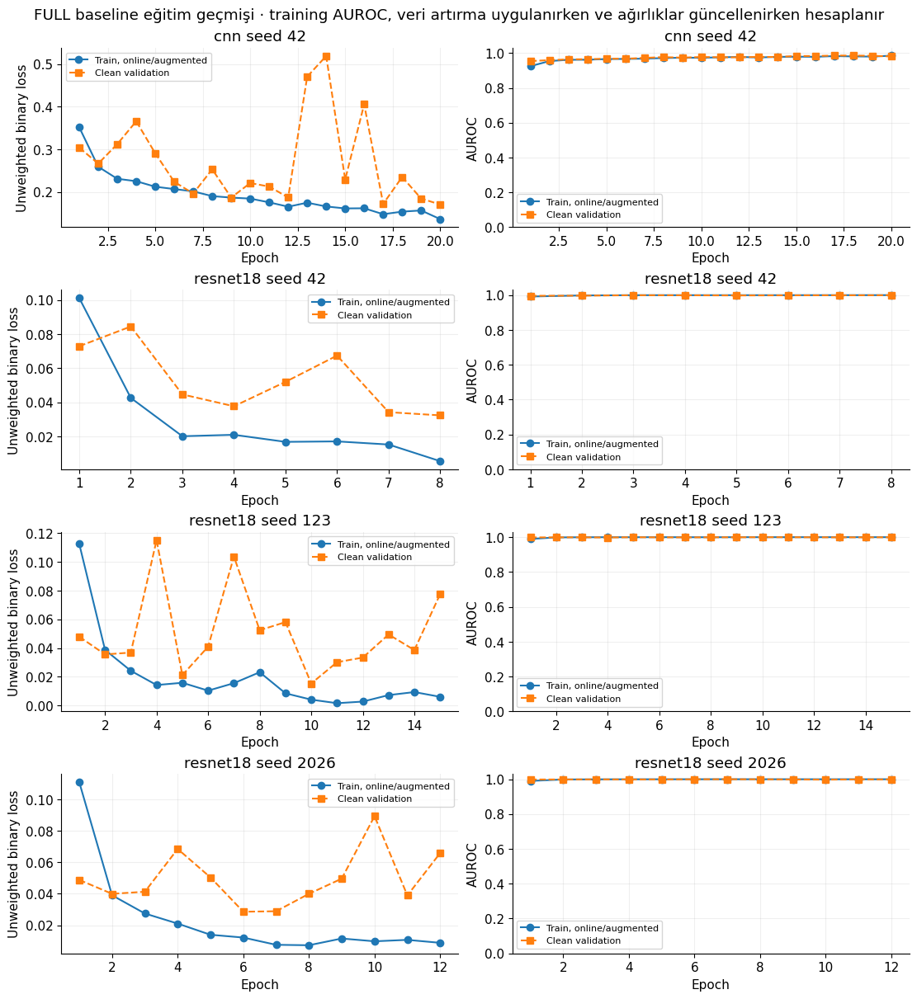

En iyi ağırlıklar ve kaynak kayıtları test öncesinde ZIP dosyasına kaydedildi: baseline_full_checkpoints.zip 124872707 bayt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

İndirme istendi; dosyanın tarayıcı tarafından kaydedildiğini kontrol edin. Kalıcı olarak saklandığı otomatik doğrulanmaz.


baseline test değerlendirmesi:   0%|          | 0/4 [00:00<?, ?checkpoint/s]

CompactCNN test clean:   0%|          | 0/10 [00:00<?, ?batch/s]

... (16 outputs left out)

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

E paired Grad-CAM:   0%|          | 0/4 [00:00<?, ?group/s]

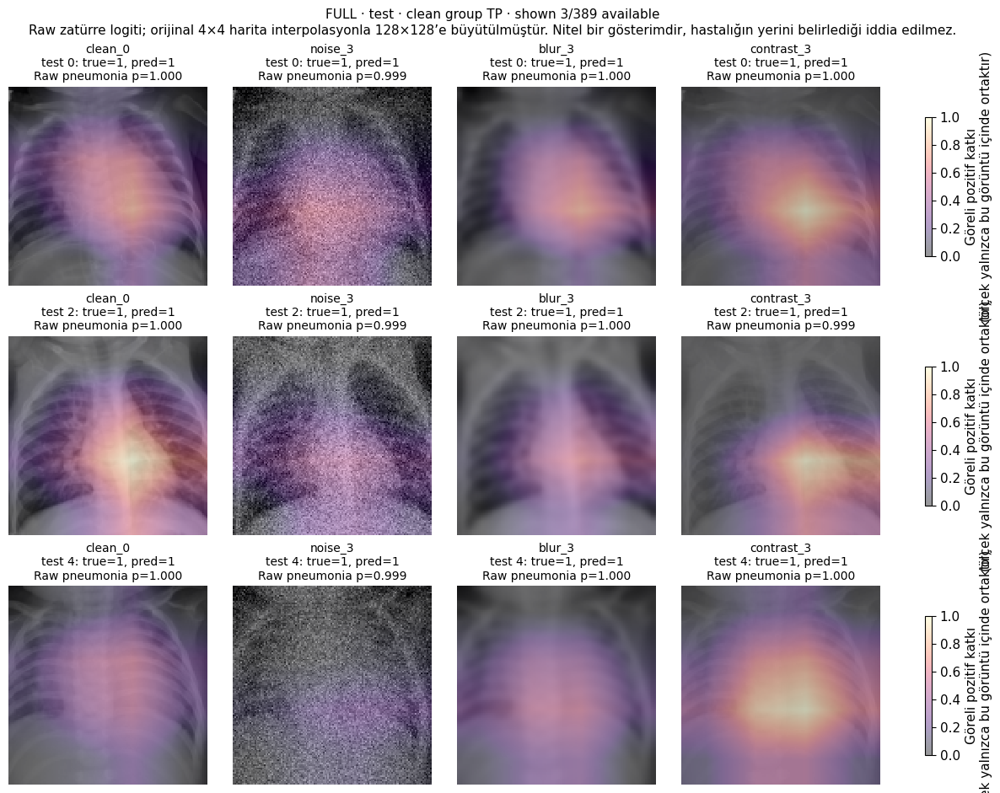

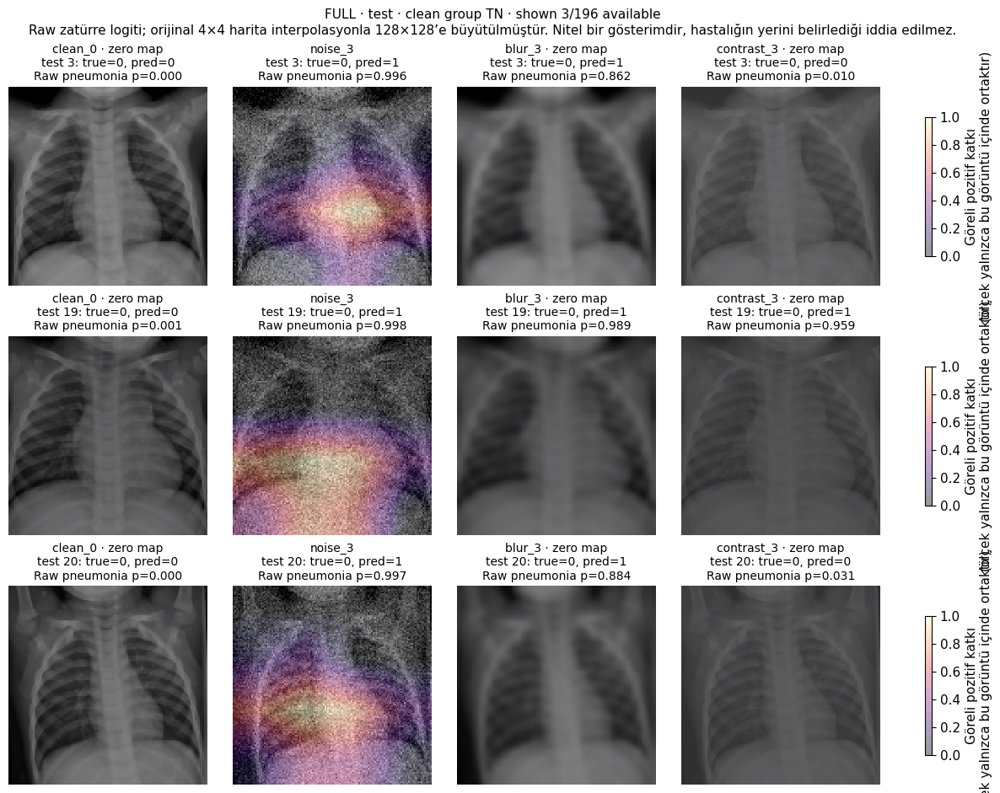

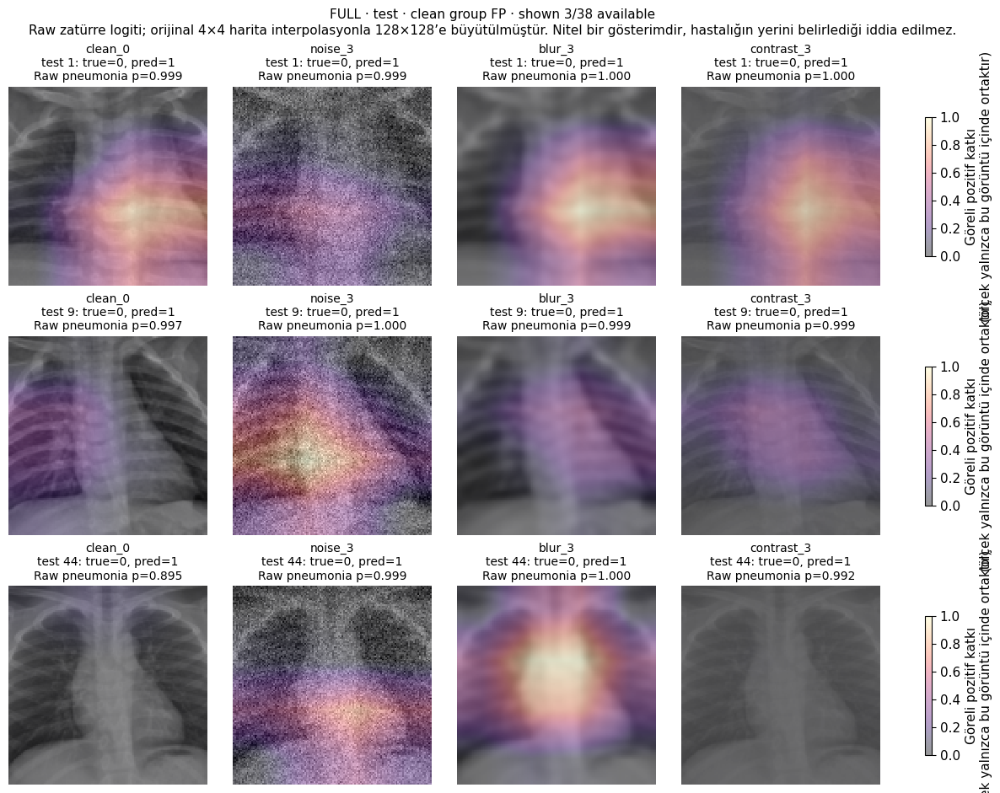

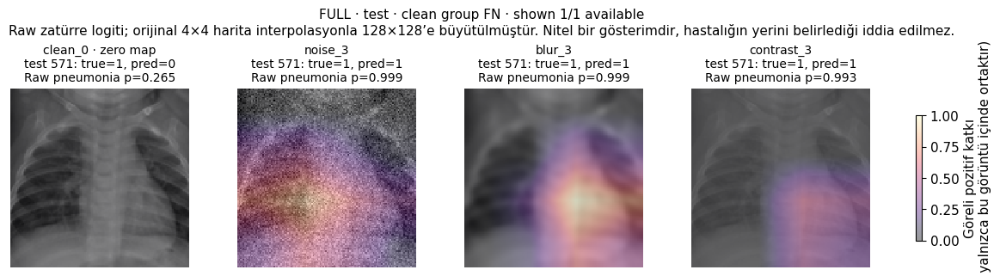

ResNet test clean:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test noise:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test noise:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test noise:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test blur:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test blur:   0%|          | 0/10 [00:00<?, ?batch/s]

... (10 outputs left out)

ResNet test blur:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

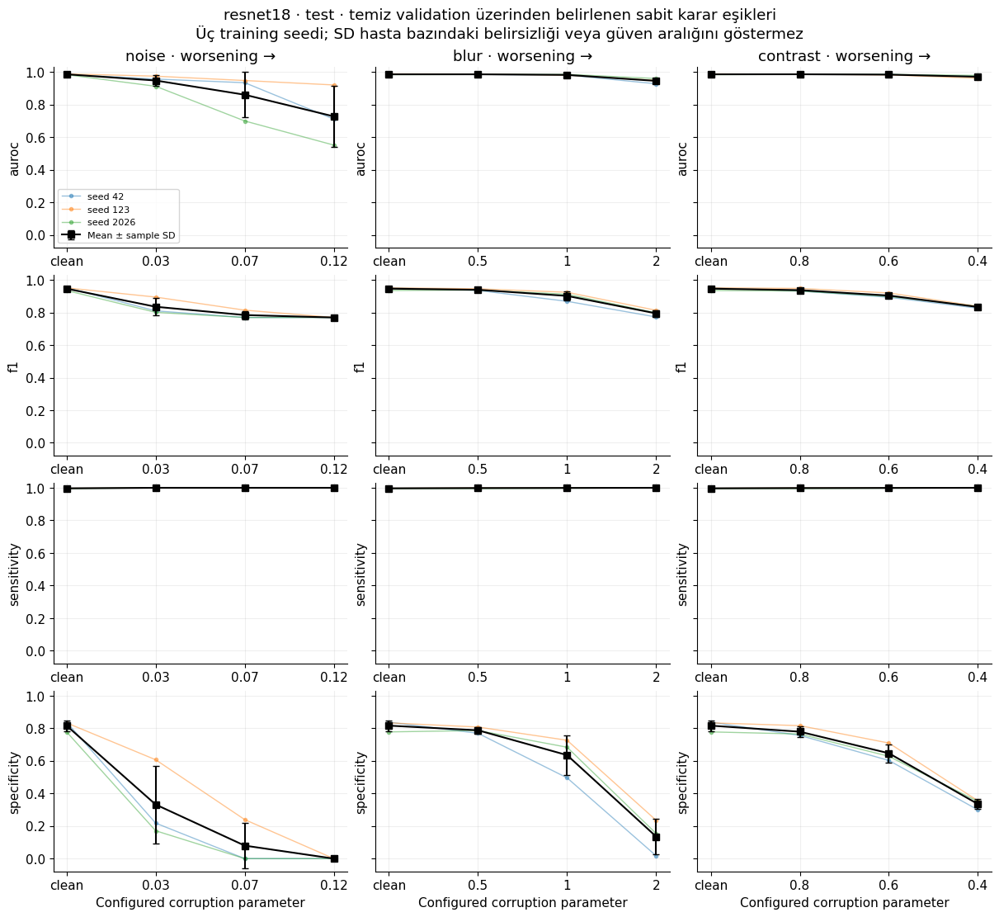

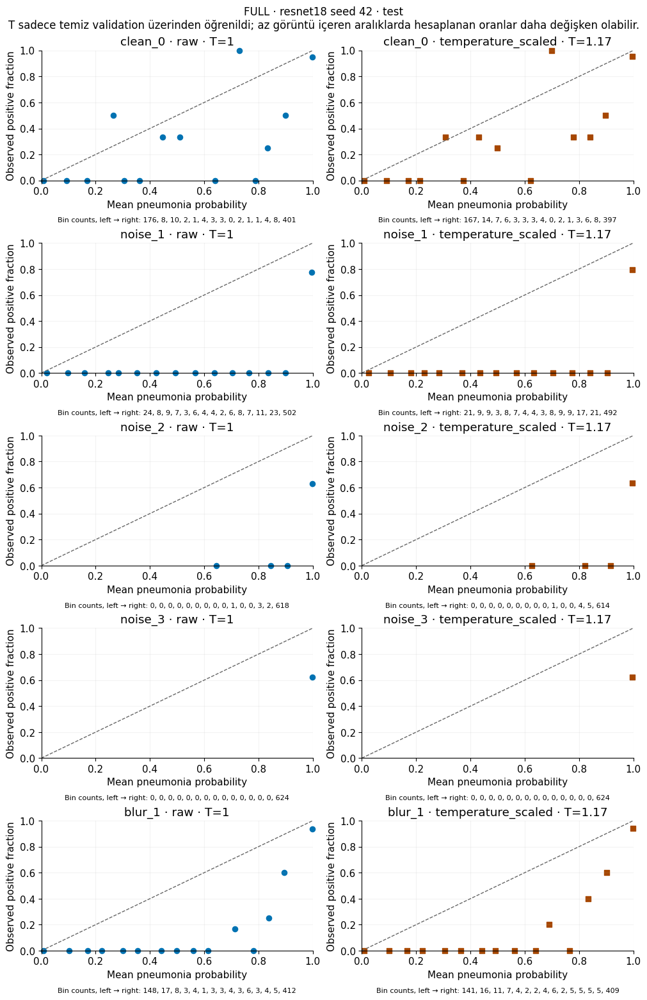

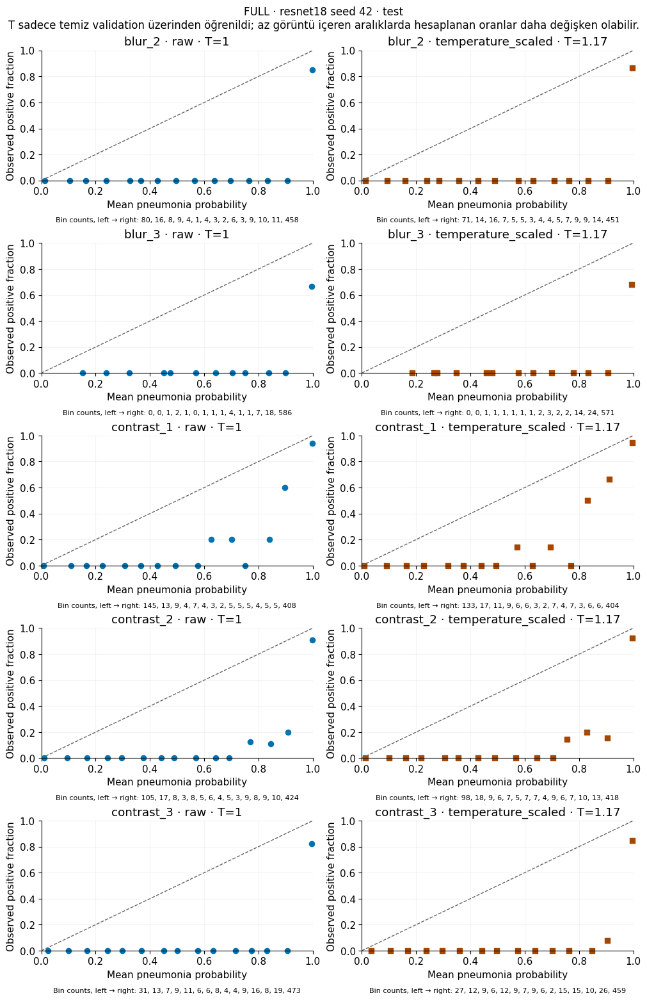

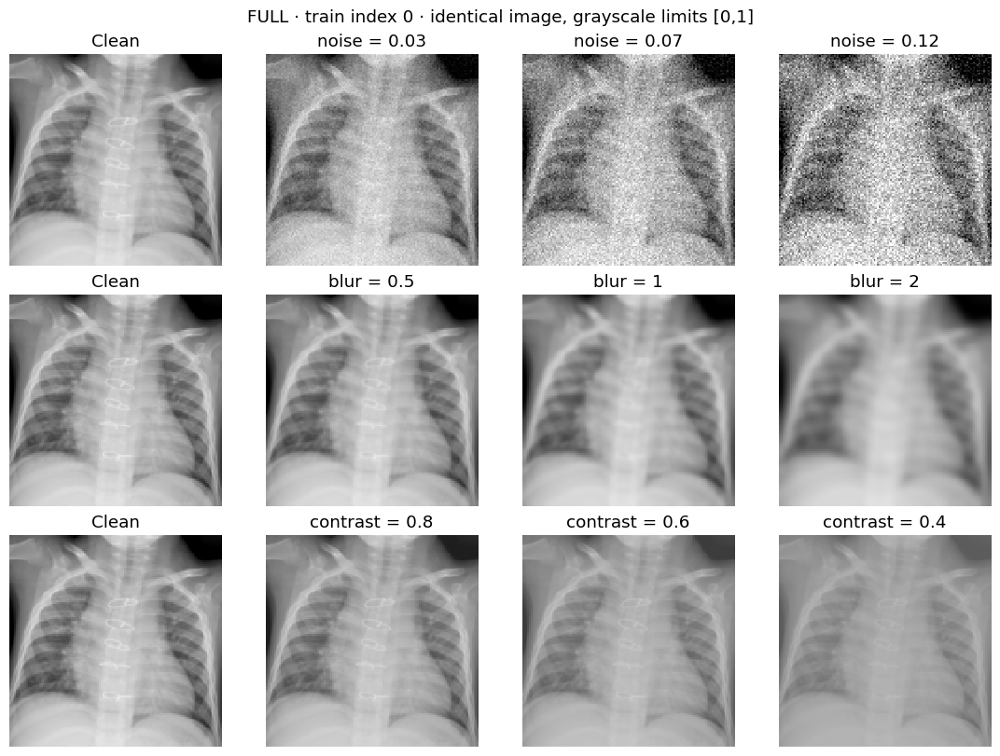

baseline Tüm değerlendirmeler tamamlandı.


robustness_v1 ana trainingler:   0%|          | 0/3 [00:00<?, ?training/s]

resnet18 seed=42 epochs:   0%|          | 0/20 [00:00<?, ?epoch/s]

ResNet train:   0%|          | 0/74 [00:00<?, ?batch/s]

ResNet val clean:   0%|          | 0/9 [00:00<?, ?batch/s]

full resnet18 seed=42 epoch=1: val AUROC=0.9966


... (106 outputs left out)

ResNet train:   0%|          | 0/74 [00:00<?, ?batch/s]

ResNet val clean:   0%|          | 0/9 [00:00<?, ?batch/s]

full resnet18 seed=2026 epoch=13: val AUROC=0.9978


ResNet val clean:   0%|          | 0/9 [00:00<?, ?batch/s]

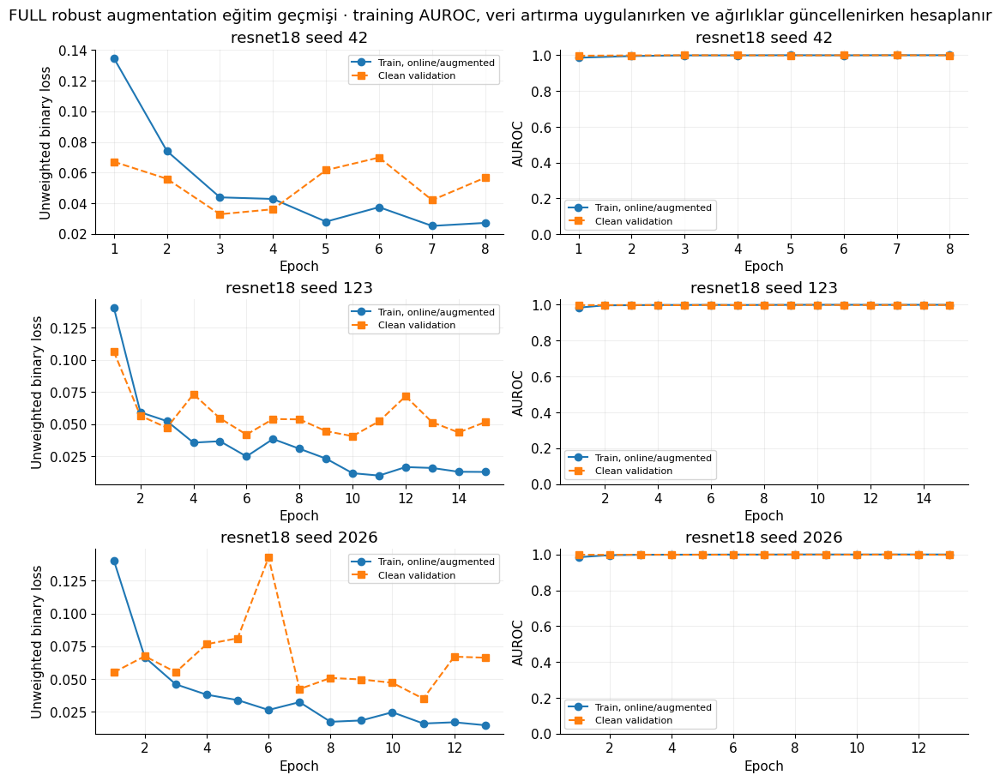

En iyi ağırlıklar ve kaynak kayıtları test öncesinde ZIP dosyasına kaydedildi: robustness_v1_full_checkpoints.zip 124758690 bayt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

İndirme istendi; dosyanın tarayıcı tarafından kaydedildiğini kontrol edin. Kalıcı olarak saklandığı otomatik doğrulanmaz.


robustness_v1 test değerlendirmesi:   0%|          | 0/3 [00:00<?, ?checkpoint/s]

ResNet test clean:   0%|          | 0/10 [00:00<?, ?batch/s]

... (25 outputs left out)

ResNet test blur:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

ResNet test contrast:   0%|          | 0/10 [00:00<?, ?batch/s]

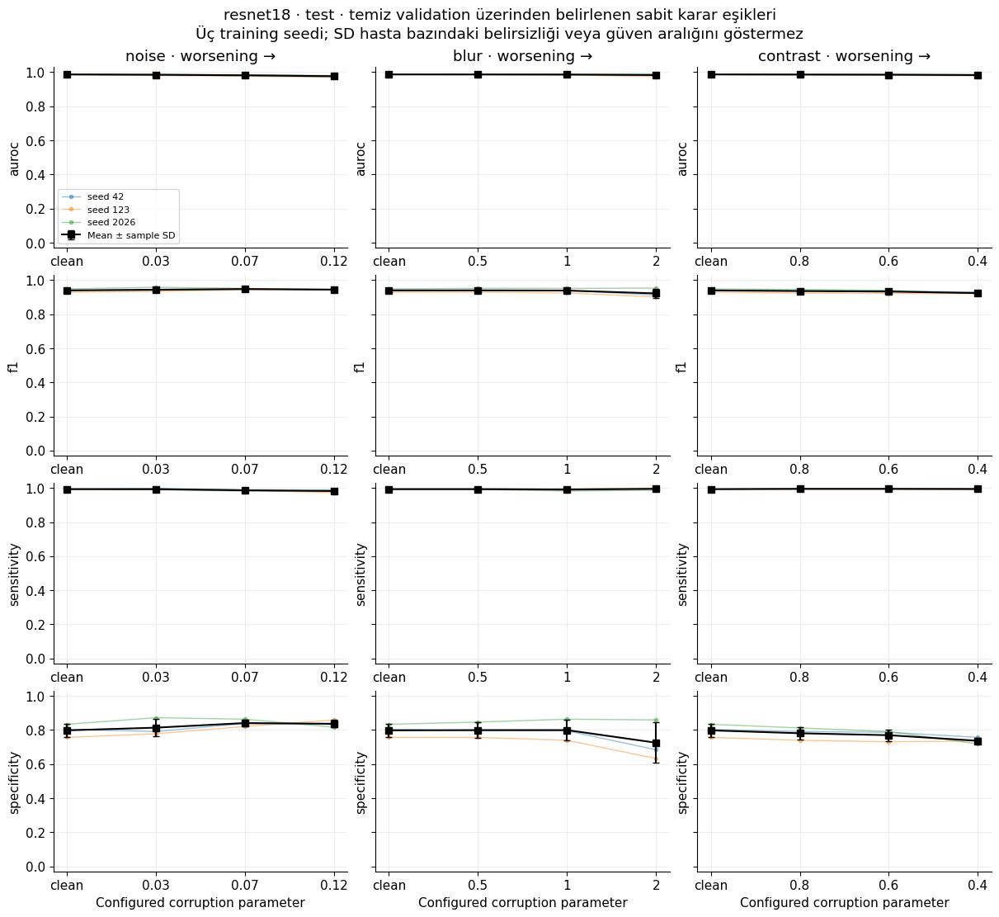

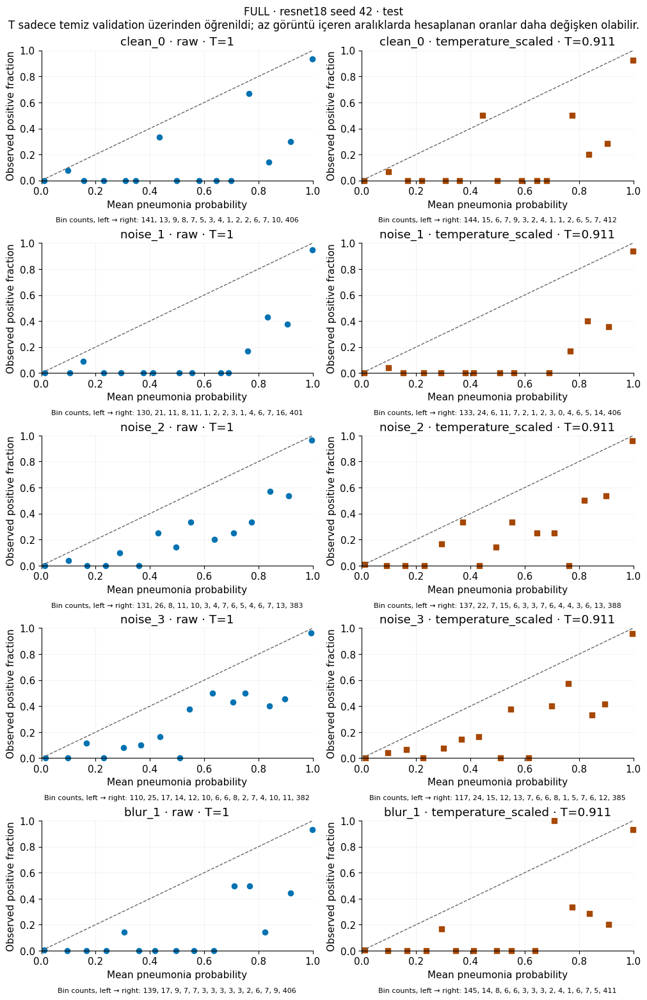

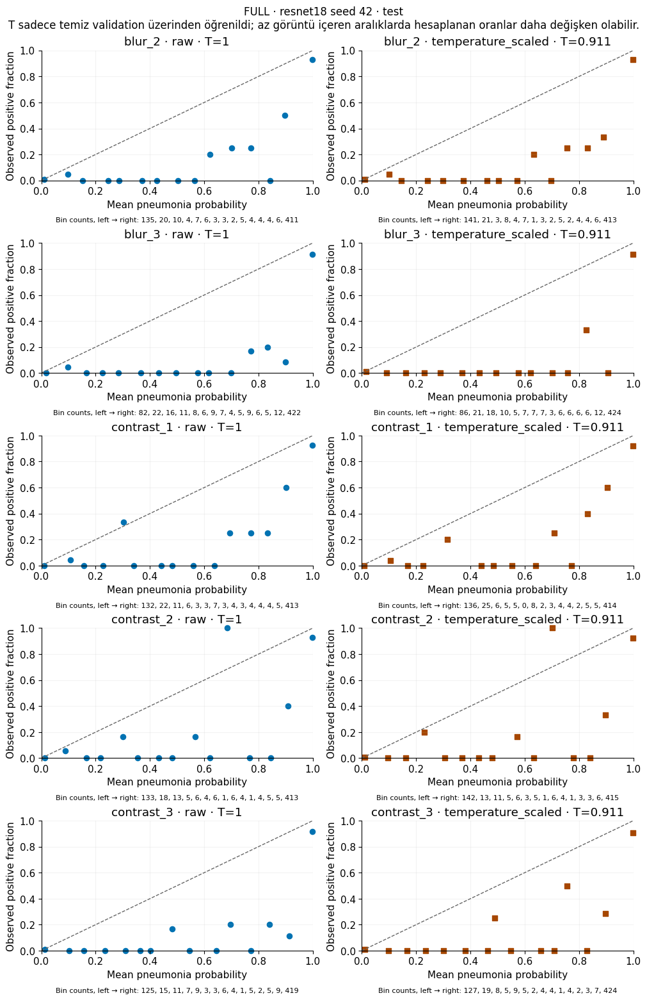

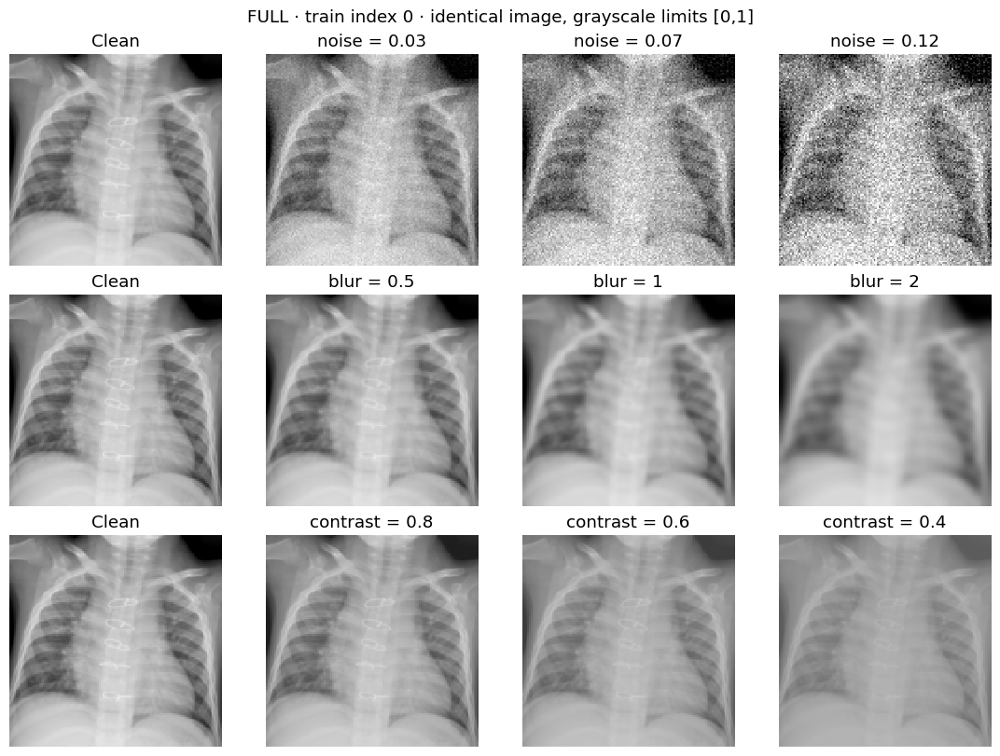

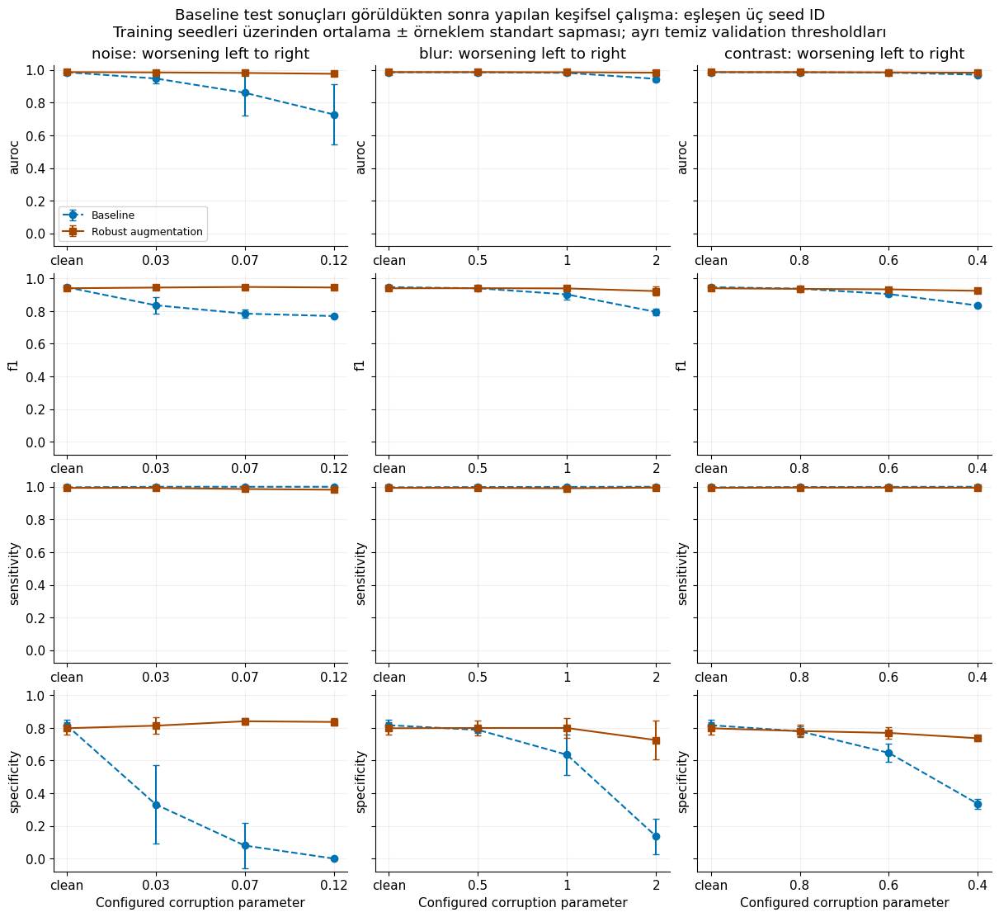

robustness_v1 Tüm değerlendirmeler tamamlandı.
Sonuçlar, grafikler, kod/ayar/runtime kayıtları ve tahmin cacheleri: /content/runs/full_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

İndirme istendi; dosyanın tarayıcı tarafından kaydedildiğini kontrol edin. Kalıcı olarak saklandığı otomatik doğrulanmaz.


,run_mode,model,seed,split,corruption_family,severity_index,parameter_value,calibration_status,decision_threshold,temperature,...,value,statistic,threshold_kind,canonical_logit_cutoff,cache,cache_sha256,checkpoint_sha256,checkpoint_source_sha256,consumer_source_sha256,consumer_config_sha256
1118,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.985795,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1119,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.989961,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1120,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.906410,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1121,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.061465,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1122,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.068447,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1123,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.946101,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1124,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,1.333333,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1125,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,43.000000,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1126,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.329595,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1127,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.996581,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,run_mode,model,seed,split,corruption_family,severity_index,parameter_value,calibration_status,decision_threshold,temperature,...,value,statistic,threshold_kind,canonical_logit_cutoff,cache,cache_sha256,checkpoint_sha256,checkpoint_source_sha256,consumer_source_sha256,consumer_config_sha256
858,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.986909,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
859,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.991300,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
860,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.895442,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
861,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.067774,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
862,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.075261,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
863,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.939445,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
864,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,2.666667,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
865,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,47.333333,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
866,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.341536,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
867,full,resnet18,aggregate_42_123_2026,test,clean,0,0.0,raw,NaN,NaN,...,0.993162,mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# study-cell: run
CODE_SNAPSHOT, code_sha256 = executed_code_snapshot()
runtime.update({'code_sha256': code_sha256,
                'source_identity_method': 'latest executed named code cells; not a whole-notebook file hash'})
calibration_test_results = calibration_checks()
baseline_run = execute_recipe('baseline')
robustness_run = None
if cfg['robustness']['enabled']:
    if MODE == 'smoke' or baseline_run['selected'] == 'resnet18':
        robustness_run = execute_recipe('robustness_v1', baseline=baseline_run)
    else:
        print('Dayanıklı ResNet karşılaştırması atlandı: bu çalıştırmada temiz validation üzerinden CNN seçildi.')
generated_results_zip = package_generated_results()
if MODE == 'smoke':
    for recipe in ['baseline', 'robustness_v1']:
        smoke_output = local_path(cfg['paths']['outputs']) / recipe / MODE
        smoke_cache = local_path(cfg['paths']['prediction_cache']) / recipe / MODE
        assert not list(smoke_output.rglob('test_exposure.json'))
        assert not any('_test_' in p.name for p in smoke_cache.rglob('*'))
    print('SMOKE BAŞARILI: test inference yapılmadı, test verisi kullanılmadı ve seedler üzerinden bilimsel özet hesaplanmadı.')
else:
    display(baseline_run['results'].query("statistic == 'mean' and corruption_family == 'clean'"))
    if robustness_run is not None:
        display(robustness_run['results'].query("statistic == 'mean' and corruption_family == 'clean'"))


## Referans Kaynaklar

- [MedMNIST](https://medmnist.com/) ve [resmî kod deposu](https://github.com/MedMNIST/MedMNIST),
  [başlangıç notebooku](https://colab.research.google.com/github/MedMNIST/MedMNIST/blob/main/examples/getting_started.ipynb).
- [PyTorch transfer learning örneği](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html),
  [ResNet-18 ağırlıkları ve normalizasyonu](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).
- [GaussianBlur](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.GaussianBlur.html),
  [GaussianNoise](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.v2.GaussianNoise.html),
  [adjust_contrast](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.functional.adjust_contrast.html).
- [Guo ve arkadaşları (2017), On Calibration of Modern Neural Networks](https://proceedings.mlr.press/v70/guo17a.html).
- [Captum LayerGradCam](https://captum.ai/api/layer.html#gradcam),
  [scikit-learn ROC thresholdları](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html),
  [average precision tanımı](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
